# P1-A8: Semantic Relationships and Retrieval

**QuadConnect · The Connectors · Team 13 · INFO 490, Fall 2026**

A retrieval-augmented generation (RAG) system that answers students' questions about QuadConnect from its student
handbook. It turns the handbook into chunks, embeds them, retrieves the chunks closest to a question, and lets a
language model answer from them:

**handbook → chunks → embeddings → vector store → top-k chunks → prompt → language model → answer**

| Part | What it does | Status |
|---|---|---|
| 1. Build the RAG pipeline | The knowledge base, three chunking strategies, three embedding models, retrieval and generation | Done |
| 2. System experiments | 3 embedding models × 3 chunking strategies = 9 configurations, tested on realistic questions | Done |
| 3. Failure analysis and improvement | Failures, their causes, and one fix shown before and after | In progress (done up to Step 3.2) |
| 4. System design reflection | Cost, RAG against its alternatives, and a design for 10,000 users a day | Next |

This notebook is independent of the Django app: it only uses QuadConnect's handbook and, for Step 2.5, its staff
guide, both in `data/`.

**To run:** `pip install -r requirements.txt` in this folder, then *Run All*. The first run downloads the three
embedding models from Hugging Face (about 1.9 GB). The language model's replies are saved in
`results/generations.jsonl`, so a re-run reuses them and needs no API key. A new question needs `GROQ_API_KEY` in
`../.env` (never committed). Every path is relative to this folder.

In [1]:
# Setup: imports, paths and the settings every step uses. Run this cell first.
import os
import platform
import re
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*symlinks.*")  # Windows without Developer Mode copies files instead
warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars need ipywidgets; not needed here

from dotenv import load_dotenv

load_dotenv(Path("..") / ".env")  # before the Hugging Face libraries load: HF_TOKEN (optional) speeds up downloads

import pandas as pd
import sentence_transformers
import torch
from huggingface_hub.utils import disable_progress_bars
from huggingface_hub.utils import logging as hub_logging
from IPython.display import display
from transformers.utils import logging as hf_logging

disable_progress_bars()
hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
DATA, RESULTS = Path("data"), Path("results")
RESULTS.mkdir(exist_ok=True)
GROQ_API_KEY = os.getenv("GROQ_API_KEY") or None  # needed only for a question whose answer is not saved yet

FIXED_WORDS = 120  # Step 1.2: the size of a fixed-length chunk, about one handbook paragraph
LONG_PARAGRAPH = 150  # Step 1.2: the hybrid strategy splits a paragraph longer than this
TOP_K = 3  # Step 1.4: chunks retrieved for each question
print(f"{platform.platform()} | {os.cpu_count()} logical CPUs | torch {torch.__version__} | "
      f"sentence-transformers {sentence_transformers.__version__}")
print(f"GROQ_API_KEY: {'set' if GROQ_API_KEY else 'not set (saved answers only)'}")


def require(condition, message):
    """Stop the notebook with the reason if a check fails."""
    if not condition:
        raise RuntimeError(message)

Windows-10-10.0.26300-SP0 | 16 logical CPUs | torch 2.14.1+cpu | sentence-transformers 6.2.0
GROQ_API_KEY: set


## Step 1.1: Define the knowledge base

**The dataset is QuadConnect's student handbook** (`data/handbook.md`): the help guide a student would read to
understand the app. It is the natural knowledge base for QuadConnect, because the questions students ask are about
how the app works: how matching decides, which times and places are possible, what happens to their feedback and
their data.

QuadConnect had no such document. Its database holds short fields (4 venues, 28 interests, 33 feedback notes), and
the repository's documents are written for developers. So we wrote the handbook for this assignment, from the app's
own code and pages. Every fact in it is one the app enforces or shows:

* the formats and preferences come from `connect/models.py`: Friend Connect (1-on-1) and Squad Connect (4 to 8
  students), the five-step social energy scale, weekends only in four two-hour windows, the 0–100 fit score and the
  check-in code;
* the venues, their seats and arrival notes, the interests and the colleges come from the seeded database;
* sign-in, cookies and data sharing come from the Privacy page and the settings, the venue check from
  `connect/ai_venues.py`, and search from the search pages.

**How the document is organised:** 13 sections, each about one subject, each made of paragraphs. A *paragraph* is a
block of text between blank lines under a `## ` section heading; headings are not paragraphs. Each paragraph covers
one idea, and the last section is a set of questions and answers, one question per paragraph. The table below checks
the brief's size requirements.

In [2]:
def read_handbook(path):
    """The handbook as paragraphs: one row per block of text between blank lines, under its section heading."""
    rows, section, number = [], None, 0
    for block in re.split(r"\n\s*\n", path.read_text(encoding="utf-8").strip()):
        block = " ".join(block.split())
        if block.startswith("## "):  # a section heading, such as "## 4. Setting your availability"
            section, number = block[3:], 0
            continue
        if block.startswith("# "):  # the document's title
            continue
        number += 1
        rows.append({"Paragraph": f"S{int(section.split('.')[0]):02d}-P{number}", "Section": section,
                     "Words": len(block.split()), "Text": block})
    return pd.DataFrame(rows)


handbook = read_handbook(DATA / "handbook.md")
words = handbook["Words"]
requirements = pd.DataFrame([
    ("Number of paragraphs", "at least 20; 30-50 recommended", f"{len(handbook)}", 30 <= len(handbook) <= 50),
    ("Paragraph length", "about 80-200 words each", f"{words.min()} to {words.max()} words (mean {words.mean():.0f})",
     words.between(80, 200).all()),
    ("Total size", "2,000-5,000 words", f"{words.sum():,} words", 2_000 <= words.sum() <= 5_000),
], columns=["Size requirement (brief, Step 1.2)", "The brief asks for", "The handbook has", "Met"])
display(requirements)
require(requirements["Met"].all(), "the knowledge base does not meet the brief's size requirements")

sections = handbook.groupby("Section", sort=False).agg(Paragraphs=("Paragraph", "count"), Words=("Words", "sum"))
display(sections)
print("One paragraph, as the pipeline sees it:\n")
print(handbook.loc[handbook["Paragraph"] == "S06-P2", ["Paragraph", "Section", "Words"]].to_string(index=False))
print(handbook.loc[handbook["Paragraph"] == "S06-P2", "Text"].iloc[0])

,"Size requirement (brief, Step 1.2)",The brief asks for,The handbook has,Met
0,Number of paragraphs,at least 20; 30-50 recommended,44,True
1,Paragraph length,about 80-200 words each,90 to 165 words (mean 111),True
2,Total size,"2,000-5,000 words","4,875 words",True


,Paragraphs,Words
Section,,
1. About QuadConnect,3,353
2. Creating an account and signing in,3,346
3. Building your profile,5,594
4. Setting your availability,2,222
5. How weekly matching works,4,473
"6. Meeting up: venues, check-in and icebreakers",4,504
7. Suggesting a new venue,4,466
8. Finding students,4,419
9. After the meetup: feedback,3,290


One paragraph, as the pipeline sees it:

Paragraph                                         Section  Words
   S06-P2 6. Meeting up: venues, check-in and icebreakers    165
Each venue page tells you how to find your group. It gives the street address, says whether the place is indoors or outdoors and how many people it seats, and adds an arrival note that says exactly where to wait. At the Illini Union you meet at the main entrance, in the ground floor lobby. At the Grainger Engineering Library you meet in the first floor commons. At the Main Quad, the only outdoor venue, you meet at the south end, by the Alma Mater statue. At Espresso Royale on Goodwin you meet in the counter seating area. The Illini Union seats twelve people, the Grainger Engineering Library eight, the Main Quad twenty and Espresso Royale six. A full squad of eight therefore fits every venue except Espresso Royale, which suits Friend Connect meetups and smaller squads. If you are not sure where to go, open the venue pa

## Step 1.2: Text representation and chunking

**Paragraphs** are defined in Step 1.1: a block of text between blank lines, under a section heading. A section is
about one subject, so **a section boundary is a topic boundary**, and no chunk may cross one.

**Sentences** end at `.`, `!` or `?` followed by a space and a capital letter, a digit or a quote. The handbook avoids
abbreviations with full stops (it says "for example", not "e.g."), so a sentence never ends early; the code below
checks that every sentence it finds starts with a capital and ends with punctuation.

**The three strategies.** None of them splits a sentence, and none puts two sections in one chunk:

| Strategy | How a chunk is made |
|---|---|
| 1. Fixed length | Whole sentences are packed, in order, into chunks of at most 120 words, about one paragraph's length. Paragraph boundaries are ignored, but each section starts a new chunk. A sentence that would push a chunk past the limit starts the next chunk instead of being cut. |
| 2. Overlapping paragraphs | Each chunk is two adjacent paragraphs of the same section: paragraphs 1 + 2, then 2 + 3, and so on. |
| 3. Hybrid (structure-aware) | One paragraph per chunk, because a handbook paragraph is one idea, with its section title in front so that the chunk names its topic. A paragraph over 150 words is split in two at the sentence boundary nearest its middle, and both halves keep the title. A question in the FAQ stays in the same chunk as its answer. |

**How the overlap is implemented:** a window two paragraphs wide slides through each section one paragraph at a time
(a stride of one). Neighbouring chunks therefore share a whole paragraph, half of each chunk, and every paragraph
except a section's first and last appears in two chunks. The window restarts at each section, so a pair never
mixes two topics; a section of a single paragraph would become one chunk on its own.

The checks after the code prove the rules on every chunk: each one is a run of whole sentences from the handbook,
each comes from one section, and together the chunks of every strategy contain every sentence of the handbook.

In [3]:
import matplotlib.pyplot as plt
import numpy as np

SENTENCE_END = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")


def sentences(text):
    return SENTENCE_END.split(text.strip())


handbook["Sentences"] = handbook["Text"].map(sentences)
odd = [s for group in handbook["Sentences"] for s in group
       if not re.match(r"[A-Z0-9\"'(]", s) or not re.search(r"[.!?][\"')]?$", s)]
require(not odd, f"the sentence splitter met something unexpected: {odd[:3]}")
print(f"{handbook['Sentences'].map(len).sum()} sentences in {len(handbook)} paragraphs, all split cleanly")


def make_chunk(strategy, number, section, paragraphs, body, heading=""):
    return {"Chunk": f"{strategy[:3].lower()}-{number:02d}", "Strategy": strategy, "Section": section,
            "Paragraphs": tuple(dict.fromkeys(paragraphs)), "Words": len(body.split()), "Heading": heading,
            "Body": body, "Text": f"{heading}\n{body}" if heading else body}


def fixed_length(book, max_words=FIXED_WORDS):
    """Whole sentences packed into chunks of at most max_words; each section starts a new chunk."""
    chunks = []
    for section, part in book.groupby("Section", sort=False):
        current, sources = [], []
        for row in part.itertuples():
            for sentence in row.Sentences:
                if current and len(" ".join(current + [sentence]).split()) > max_words:
                    chunks.append(make_chunk("Fixed", len(chunks) + 1, section, sources, " ".join(current)))
                    current, sources = [], []
                current.append(sentence)
                sources.append(row.Paragraph)
        chunks.append(make_chunk("Fixed", len(chunks) + 1, section, sources, " ".join(current)))
    return pd.DataFrame(chunks)


def overlapping(book):
    """Two adjacent paragraphs of the same section per chunk, with a stride of one paragraph."""
    chunks = []
    for section, part in book.groupby("Section", sort=False):
        rows = list(part.itertuples())
        pairs = list(zip(rows, rows[1:], strict=False)) or [(rows[0],)]  # a one-paragraph section stays one chunk
        for pair in pairs:
            chunks.append(make_chunk("Overlapping", len(chunks) + 1, section, [r.Paragraph for r in pair],
                                     "\n\n".join(r.Text for r in pair)))
    return pd.DataFrame(chunks)


def hybrid(book, long=LONG_PARAGRAPH):
    """One paragraph per chunk, titled with its section; a paragraph over `long` words is halved at a sentence."""
    chunks = []
    for row in book.itertuples():
        title = row.Section.split(". ", 1)[1]  # "4. Setting your availability" -> "Setting your availability"
        parts = [row.Sentences]
        if row.Words > long:
            running = np.cumsum([len(s.split()) for s in row.Sentences])
            cut = int(np.argmin(np.abs(running[:-1] - row.Words / 2))) + 1  # the boundary nearest the middle
            parts = [row.Sentences[:cut], row.Sentences[cut:]]
        for part in parts:
            chunks.append(make_chunk("Hybrid", len(chunks) + 1, row.Section, [row.Paragraph], " ".join(part),
                                     heading=f"{title}:"))
    return pd.DataFrame(chunks)


CHUNKS = {"Fixed": fixed_length(handbook), "Overlapping": overlapping(handbook), "Hybrid": hybrid(handbook)}

261 sentences in 44 paragraphs, all split cleanly


In [4]:
# The rules, checked on every chunk of every strategy.
all_sentences = [s for group in handbook["Sentences"] for s in group]
section_of = dict(zip(handbook["Paragraph"], handbook["Section"], strict=True))
checks = []
for name, table in CHUNKS.items():
    found = [s for body in table["Body"] for s in sentences(body)]
    whole = all(s in all_sentences for s in found)  # a cut sentence would not be in the handbook's list
    one_section = all(len({section_of[p] for p in ps}) == 1 for ps in table["Paragraphs"])
    complete = set(all_sentences) <= set(found)
    checks.append({"Strategy": name, "Chunks": len(table), "No sentence split": whole,
                   "No chunk crosses a section": one_section, "Every sentence covered": complete,
                   "Words per chunk (min-max)": f"{table['Words'].min()}-{table['Words'].max()}",
                   "Mean words": round(table["Words"].mean()),
                   "Paragraphs per chunk": round(table["Paragraphs"].map(len).mean(), 2),
                   "Chunks per paragraph": round(table["Paragraphs"].map(len).sum() / len(handbook), 2)})
checks = pd.DataFrame(checks).set_index("Strategy")
display(checks)
require(checks[["No sentence split", "No chunk crosses a section", "Every sentence covered"]].all().all(),
        "a chunk breaks a rule")

pairs = CHUNKS["Overlapping"]["Paragraphs"].tolist()
shared = [len(set(a) & set(b)) for a, b in zip(pairs, pairs[1:], strict=False) if section_of[a[0]] == section_of[b[0]]]
print(f"Overlap: neighbouring chunks in a section share {min(shared)} paragraph each ({len(shared)} pairs).")
split = CHUNKS["Hybrid"][CHUNKS["Hybrid"]["Paragraphs"].duplicated(keep=False)]
print(f"Hybrid: {split['Paragraphs'].nunique()} paragraphs over {LONG_PARAGRAPH} words were halved: "
      + ", ".join(sorted({p[0] for p in split['Paragraphs']})))
CHUNKS_ALL = pd.concat(CHUNKS.values(), ignore_index=True)
CHUNKS_ALL.assign(Paragraphs=CHUNKS_ALL["Paragraphs"].map(" ".join)).drop(columns="Body").to_csv(
    RESULTS / "chunks.csv", index=False, lineterminator="\n")
print(f"All {len(CHUNKS_ALL)} chunks saved to results/chunks.csv")

,Chunks,No sentence split,No chunk crosses a section,Every sentence covered,Words per chunk (min-max),Mean words,Paragraphs per chunk,Chunks per paragraph
Strategy,,,,,,,,
Fixed,50,True,True,True,21-120,98,1.46,1.66
Overlapping,31,True,True,True,186-285,222,2.00,1.41
Hybrid,48,True,True,True,67-122,102,1.00,1.09


Overlap: neighbouring chunks in a section share 1 paragraph each (18 pairs).
Hybrid: 4 paragraphs over 150 words were halved: S03-P5, S05-P3, S06-P2, S07-P4
All 129 chunks saved to results/chunks.csv


=== Fixed
[fix-15] paragraphs S04-P1, S04-P2 | 116 words
   QuadConnect meetups happen only on weekends, so your availability is a set of weekend time windows. You can mark Saturday, Sunday or both, and each day has four two-hour windows: 10 AM to 12 PM, 12 to 2 PM, 2 to 4 PM and 4 to 6 PM. That gives eight possible slots in a week, and you can mark as many of them as you like. Each slot can be marked only once, so marking Saturday from 2 to 4 PM twice is not possible. All the windows fall in the daytime, between 10 AM and 6 PM, so every QuadConnect meetup takes place during the day. Availability is the one hard rule in matching.
[fix-16] paragraphs S04-P2 | 106 words
   Two students can be matched only if they share at least one free slot, because a meetup needs a time that everyone can make. Interests and preferences decide how good a match is, but a shared slot decides whether a match is possible at all. That makes your availability the most important part of your profile to keep up

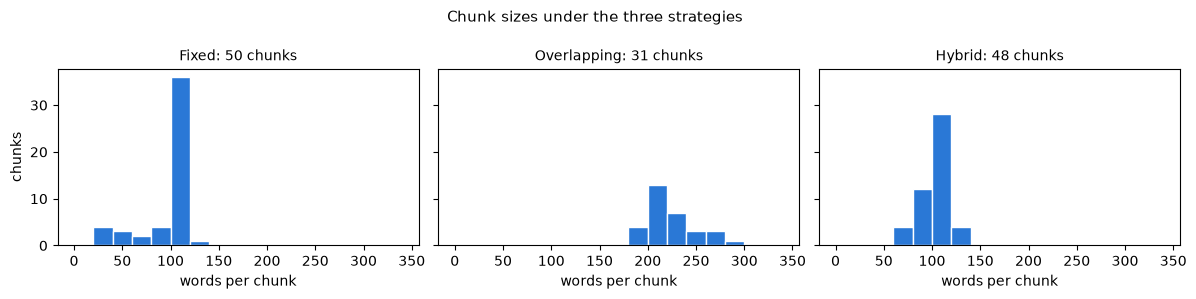

In [5]:
# One section under each strategy: Section 4, "Setting your availability" (two paragraphs).
for name, table in CHUNKS.items():
    print(f"=== {name}")
    for row in table[table["Section"].str.startswith("4.")].itertuples():
        print(f"[{row.Chunk}] paragraphs {', '.join(row.Paragraphs)} | {row.Words} words")
        print("   " + row.Text.replace("\n", "\n   ")[:600] + (" ..." if len(row.Text) > 600 else ""))
    print()

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, table) in zip(axes, CHUNKS.items(), strict=True):
    ax.hist(table["Words"], bins=range(0, 360, 20), color="#2a78d6", edgecolor="white")
    ax.set_title(f"{name}: {len(table)} chunks", fontsize=10)
    ax.set_xlabel("words per chunk")
axes[0].set_ylabel("chunks")
fig.suptitle("Chunk sizes under the three strategies", fontsize=11)
plt.tight_layout()
plt.show()

## Step 1.3: Embedding pipeline

**Three embedding models of different sizes**, all free on Hugging Face and loaded with `sentence-transformers`:

| Size | Model | Parameters | Dimensions |
|---|---|---|---|
| Small | `BAAI/bge-small-en-v1.5` | 33 million | 384 |
| Medium | `BAAI/bge-base-en-v1.5` | 109 million | 768 |
| Large | `BAAI/bge-large-en-v1.5` | 335 million | 1,024 |

We sort them by the length of the vectors they produce, the brief's categories (about 384, about 768, and 1,024 to
1,536). All three come from the same family, BAAI's BGE v1.5, trained the same way, so the main difference between
them is size. That keeps the comparison in Part 2 fair: a change in retrieval comes from the model's size, not from a
different training recipe.

**Embedding:** each chunk's text, title included, becomes one vector, scaled to length 1 so that the cosine
similarity of two vectors is simply their dot product. A question gets BGE's retrieval instruction in front, as its
model card recommends for short queries; the chunks do not.

**The searchable structure:** one `VectorStore` per model and strategy, nine in all. It holds a matrix with one row per
chunk and the chunk table beside it. A search multiplies the matrix by the question's vector and returns the
highest-scoring rows. The search is exact: every chunk is scored, and for a few hundred chunks the whole search,
including building the result table, takes a few milliseconds (Step 1.4 times it). Part 4 covers what changes at
scale.

**Checks:** no chunk is longer than the model's 512-token input, so nothing is cut off before it is embedded; and
every chunk, searched with its own vector, finds itself first.

In [6]:
import time

from sentence_transformers import SentenceTransformer

EMBEDDERS = {"Small": "BAAI/bge-small-en-v1.5", "Medium": "BAAI/bge-base-en-v1.5", "Large": "BAAI/bge-large-en-v1.5"}
QUERY_INSTRUCTION = "Represent this sentence for searching relevant passages: "  # BGE v1.5 model cards


class VectorStore:
    """One embedding model's vectors for one chunking strategy, searched by cosine similarity."""

    def __init__(self, embedder, chunks):
        self.embedder, self.chunks = embedder, chunks.reset_index(drop=True)
        started = time.perf_counter()
        self.vectors = embedder.encode(self.chunks["Text"].tolist(), batch_size=16, normalize_embeddings=True,
                                       convert_to_numpy=True).astype(np.float32)
        self.index_seconds = time.perf_counter() - started

    def embed_query(self, query):
        return self.embedder.encode(QUERY_INSTRUCTION + query, normalize_embeddings=True, convert_to_numpy=True)

    def search(self, query_vector, k=TOP_K):
        scores = self.vectors @ query_vector  # cosine similarity: every vector has length 1
        top = np.argsort(-scores)[:k]
        return self.chunks.iloc[top].assign(Rank=range(1, len(top) + 1), Score=scores[top].round(4))


MODELS, STORES, stats = {}, {}, []
for size, model_id in EMBEDDERS.items():
    started = time.perf_counter()
    MODELS[size] = SentenceTransformer(model_id, device="cpu")
    load_s = time.perf_counter() - started
    embedder = MODELS[size]
    for name, table in CHUNKS.items():
        STORES[size, name] = store = VectorStore(embedder, table)
        longest = max(len(embedder.tokenizer(text)["input_ids"]) for text in table["Text"])
        hits = [int(np.argmax(store.vectors @ store.vectors[i])) == i for i in range(len(table))]
        stats.append({"Size": size, "Model": model_id, "Parameters (M)": round(sum(p.numel() for p in
                      embedder.parameters()) / 1e6), "Dimensions": store.vectors.shape[1], "Strategy": name,
                      "Chunks": len(table), "Longest chunk (tokens)": longest, "Model limit": embedder.max_seq_length,
                      "Load (s)": round(load_s, 1), "Index (s)": round(store.index_seconds, 2),
                      "ms per chunk": round(store.index_seconds / len(table) * 1000, 1),
                      "Vectors (KB)": round(store.vectors.nbytes / 1024, 1),
                      "Finds itself first": f"{sum(hits)}/{len(hits)}"})
EMBEDDING_STATS = pd.DataFrame(stats)
display(EMBEDDING_STATS)
require((EMBEDDING_STATS["Longest chunk (tokens)"] <= EMBEDDING_STATS["Model limit"]).all(),
        "a chunk would be cut off")
require(all(s.split("/")[0] == s.split("/")[1] for s in EMBEDDING_STATS["Finds itself first"]),
        "a chunk does not find itself first")
EMBEDDING_STATS.to_csv(RESULTS / "embedding_stats.csv", index=False, lineterminator="\n")
print(f"{len(STORES)} vector stores: 3 models x 3 strategies. Saved to results/embedding_stats.csv")

,Size,Model,Parameters (M),Dimensions,Strategy,Chunks,Longest chunk (tokens),Model limit,Load (s),Index (s),ms per chunk,Vectors (KB),Finds itself first
0,Small,BAAI/bge-small-en-v1.5,33,384,Fixed,50,156,512,0.8,1.56,31.1,75.0,50/50
1,Small,BAAI/bge-small-en-v1.5,33,384,Overlapping,31,346,512,0.8,2.17,70.0,46.5,31/31
2,Small,BAAI/bge-small-en-v1.5,33,384,Hybrid,48,162,512,0.8,1.67,34.8,72.0,48/48
3,Medium,BAAI/bge-base-en-v1.5,109,768,Fixed,50,156,512,1.5,4.74,94.8,150.0,50/50
4,Medium,BAAI/bge-base-en-v1.5,109,768,Overlapping,31,346,512,1.5,6.92,223.1,93.0,31/31
5,Medium,BAAI/bge-base-en-v1.5,109,768,Hybrid,48,162,512,1.5,4.88,101.6,144.0,48/48
6,Large,BAAI/bge-large-en-v1.5,335,1024,Fixed,50,156,512,2.1,16.16,323.1,200.0,50/50
7,Large,BAAI/bge-large-en-v1.5,335,1024,Overlapping,31,346,512,2.1,22.21,716.3,124.0,31/31
8,Large,BAAI/bge-large-en-v1.5,335,1024,Hybrid,48,162,512,2.1,16.64,346.7,192.0,48/48


9 vector stores: 3 models x 3 strategies. Saved to results/embedding_stats.csv


## Step 1.4: Retrieval system

**Query → embedding → similarity search → top-k chunks.** `retrieve()` embeds the question with the same model as
the store (with the retrieval instruction), scores every chunk by cosine similarity, and returns the top k = 3 chunks
with their rank, score, section and source paragraphs. It also times the two parts: embedding the question, and the
search itself.

Below: two questions on one configuration (the medium model with hybrid chunks), and then one question on all nine
configurations, to show that every store is wired in. Part 2 measures all nine on a full set of test questions.

In [7]:
def retrieve(query, size="Medium", strategy="Hybrid", k=TOP_K):
    """The top-k chunks for a question, and how long embedding it and searching took (in milliseconds)."""
    store = STORES[size, strategy]
    started = time.perf_counter()
    vector = store.embed_query(query)
    embedded = time.perf_counter()
    hits = store.search(vector, k)
    searched = time.perf_counter()
    return hits, {"Embed query (ms)": (embedded - started) * 1000, "Search (ms)": (searched - embedded) * 1000}


SHOW = ["Rank", "Score", "Chunk", "Section", "Paragraphs", "Words"]
DEMO = ["Which venues can seat a full squad of eight?", "What does Google send to QuadConnect when I sign in?"]
for query in DEMO:
    hits, timing = retrieve(query)
    print(f"Q: {query}\n   medium model, hybrid chunks: question embedded in {timing['Embed query (ms)']:.1f} ms, "
          f"searched in {timing['Search (ms)']:.2f} ms")
    display(hits[SHOW].assign(Paragraphs=hits["Paragraphs"].map(", ".join)).set_index("Rank"))
    print("   Top chunk:", hits.iloc[0]["Text"].replace("\n", " ")[:400], "...\n")

Q: Which venues can seat a full squad of eight?
   medium model, hybrid chunks: question embedded in 55.2 ms, searched in 4.15 ms


,Score,Chunk,Section,Paragraphs,Words
Rank,,,,,
1,0.6064,hyb-19,5. How weekly matching works,S05-P4,102
2,0.5850,hyb-22,"6. Meeting up: venues, check-in and icebreakers",S06-P2,79
3,0.5252,hyb-20,"6. Meeting up: venues, check-in and icebreakers",S06-P1,120


   Top chunk: How weekly matching works: Squad matches bring four to eight students together, so they need more planning than a one-on-one coffee. Every venue records the largest group it can seat comfortably, from 2 to 50 people, so that a squad is planned for a place that fits it. A squad is also a good setting for the suggested activity, because a shared task such as board games or sports takes the pressure  ...

Q: What does Google send to QuadConnect when I sign in?
   medium model, hybrid chunks: question embedded in 53.9 ms, searched in 2.57 ms


,Score,Chunk,Section,Paragraphs,Words
Rank,,,,,
1,0.8322,hyb-05,2. Creating an account and signing in,S02-P2,111
2,0.7793,hyb-06,2. Creating an account and signing in,S02-P3,113
3,0.7553,hyb-04,2. Creating an account and signing in,S02-P1,122


   Top chunk: Creating an account and signing in: When you continue with Google, Google sends QuadConnect four things: your name, your email address, a link to your profile picture and your Google account number. QuadConnect asks Google for nothing else. It does not see your contacts, your files or your calendar, and it never sees your Google password, because you type that into Google's own page. If you later  ...



In [8]:
query = "How do I check in when I get to the meetup?"
rows = []
for (size, strategy) in STORES:
    hits, timing = retrieve(query, size, strategy)
    top = hits.iloc[0]
    rows.append({"Embedding": size, "Chunking": strategy, "Top chunk": top["Chunk"], "Score": top["Score"],
                 "Its paragraphs": ", ".join(top["Paragraphs"]), "Top-3 paragraphs": ", ".join(
                     dict.fromkeys(p for ps in hits["Paragraphs"] for p in ps)),
                 "Embed (ms)": round(timing["Embed query (ms)"], 1), "Search (ms)": round(timing["Search (ms)"], 3)})
print(f"Q: {query}  (the check-in paragraph is S06-P3)")
RETRIEVAL_DEMO = pd.DataFrame(rows)
display(RETRIEVAL_DEMO)
RETRIEVAL_DEMO.to_csv(RESULTS / "retrieval_demo.csv", index=False, lineterminator="\n")

Q: How do I check in when I get to the meetup?  (the check-in paragraph is S06-P3)


,Embedding,Chunking,Top chunk,Score,Its paragraphs,Top-3 paragraphs,Embed (ms),Search (ms)
0,Small,Fixed,fix-24,0.7584,"S06-P2, S06-P3","S06-P2, S06-P3, S10-P1, S10-P2, S07-P1",23.2,2.027
1,Small,Overlapping,ove-15,0.7582,"S06-P3, S06-P4","S06-P3, S06-P4, S06-P2, S10-P1, S10-P2",24.2,2.380
2,Small,Hybrid,hyb-23,0.7729,S06-P3,"S06-P3, S10-P2, S06-P2",21.2,2.577
3,Medium,Fixed,fix-24,0.6903,"S06-P2, S06-P3","S06-P2, S06-P3, S10-P1, S10-P2, S06-P4",54.4,2.294
4,Medium,Overlapping,ove-15,0.7229,"S06-P3, S06-P4","S06-P3, S06-P4, S06-P2, S10-P1, S10-P2",52.3,2.023
5,Medium,Hybrid,hyb-23,0.7274,S06-P3,"S06-P3, S06-P2, S10-P2",57.4,2.170
6,Large,Fixed,fix-24,0.7305,"S06-P2, S06-P3","S06-P2, S06-P3, S07-P2, S07-P3, S10-P1, S10-P2",192.7,2.842
7,Large,Overlapping,ove-15,0.7381,"S06-P3, S06-P4","S06-P3, S06-P4, S06-P2, S10-P1, S10-P2",188.9,2.349
8,Large,Hybrid,hyb-23,0.7561,S06-P3,"S06-P3, S10-P2, S10-P1",194.9,2.558


## Step 1.5: Generation pipeline

**The prompt has the three parts the brief asks for**, sent as two chat messages:

1. **System instruction:** the assistant's role and rules. It may answer only from the excerpts, must say so when
   they do not cover the question instead of guessing, keeps to four sentences, and cites the excerpts it used.
2. **Retrieved context:** the k = 3 chunks, numbered [1] to [3] in rank order, each labelled with its section.
3. **User query:** the student's question, after the context.

**The generation model is gpt-oss-20b**, one of the 15 models our team evaluated in A6 and A7. In A7 it scored 9.85
out of 10 across QuadConnect's five jobs, and 10 on summaries, the job closest to answering from given text. It runs
on Groq with A7's exact settings: temperature 0, at most 1,024 new tokens (room for its hidden reasoning as well as
the answer), and low reasoning effort. **The same model and settings are used for every answer in every experiment**,
so a difference between two configurations comes from retrieval, never from the generator.

**Replies are saved.** Each reply is stored in `results/generations.jsonl` under a hash of the model, its settings
and the whole prompt, with the time the call took. A re-run reuses the saved reply, so it needs no API key and gives
the same answer.

In [9]:
import hashlib
import json

import requests

GENERATOR = {"model": "openai/gpt-oss-20b", "temperature": 0, "max_tokens": 1024, "reasoning_effort": "low"}
GROQ_URL = "https://api.groq.com/openai/v1/chat/completions"
SYSTEM = ("You are QuadConnect's help assistant. Answer the student's question using only the handbook excerpts "
          "below. If the excerpts do not contain the answer, say that the handbook does not cover it, and do not "
          "guess. Keep the answer to at most four sentences, and cite the excerpts you used by their numbers, "
          "such as [1] or [2].")
CACHE_FILE = RESULTS / "generations.jsonl"
CACHE = {}
if CACHE_FILE.exists():
    for line in CACHE_FILE.read_text(encoding="utf-8").splitlines():
        if line.strip():
            CACHE[json.loads(line)["key"]] = json.loads(line)


def build_messages(query, hits):
    """System instruction, retrieved context and user query, as chat messages."""
    context = "\n\n".join(f"[{i}] (Section: {row.Section.split('. ', 1)[1]})\n{row.Body}"
                          for i, row in enumerate(hits.itertuples(), start=1))
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"Handbook excerpts:\n\n{context}\n\nQuestion: {query}"}]


def generate(messages):
    """The model's answer: the saved one if this exact prompt was answered before, otherwise a new call."""
    key = hashlib.sha256(json.dumps({"generator": GENERATOR, "messages": messages}, sort_keys=True).encode()).hexdigest()
    if key in CACHE:
        return CACHE[key]
    if not GROQ_API_KEY:
        return {"answer": None, "latency_s": None, "note": "not saved yet; set GROQ_API_KEY in ../.env to generate"}
    for _ in range(8):  # on a rate limit (HTTP 429), wait as told and try again
        started = time.perf_counter()
        response = requests.post(GROQ_URL, json={**GENERATOR, "messages": messages}, timeout=120,
                                 headers={"Authorization": f"Bearer {GROQ_API_KEY}"})
        latency = time.perf_counter() - started
        if response.status_code != 429:
            break
        time.sleep(float(response.headers.get("retry-after", 10)) + 1)
    response.raise_for_status()
    data = response.json()
    choice, usage = data["choices"][0], data.get("usage") or {}
    row = {"key": key, "model": GENERATOR["model"], "answer": (choice["message"].get("content") or "").strip(),
           "latency_s": round(latency, 3), "prompt_tokens": usage.get("prompt_tokens"),
           "completion_tokens": usage.get("completion_tokens"), "finished": choice.get("finish_reason") == "stop"}
    with CACHE_FILE.open("a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
    CACHE[key] = row
    return row


def ask(query, size="Medium", strategy="Hybrid", k=TOP_K):
    """The whole pipeline for one question: retrieve, build the prompt, generate. Times each part."""
    hits, timing = retrieve(query, size, strategy, k)
    messages = build_messages(query, hits)
    reply = generate(messages)
    timing["Generate (s)"] = reply.get("latency_s")
    return {"query": query, "hits": hits, "messages": messages, "answer": reply.get("answer") or reply.get("note"),
            "timing": timing, "reply": reply}

In [10]:
result = ask(DEMO[0])
print("The full prompt for the first question (medium model, hybrid chunks):\n")
for message in result["messages"]:
    print(f"--- {message['role']} ---\n{message['content']}\n")

The full prompt for the first question (medium model, hybrid chunks):

--- system ---
You are QuadConnect's help assistant. Answer the student's question using only the handbook excerpts below. If the excerpts do not contain the answer, say that the handbook does not cover it, and do not guess. Keep the answer to at most four sentences, and cite the excerpts you used by their numbers, such as [1] or [2].

--- user ---
Handbook excerpts:

[1] (Section: How weekly matching works)
Squad matches bring four to eight students together, so they need more planning than a one-on-one coffee. Every venue records the largest group it can seat comfortably, from 2 to 50 people, so that a squad is planned for a place that fits it. A squad is also a good setting for the suggested activity, because a shared task such as board games or sports takes the pressure off the conversation. Your group size preference matters here as well. A student who chose One person as their group size suits Friend Connect, 

In [11]:
DEMO_ALL = DEMO + ["Can I use QuadConnect as an app on my phone?"]  # the last one is not in the handbook
rows = []
for query in DEMO_ALL:
    out = ask(query)
    rows.append({"Question": query, "Retrieved": ", ".join(out["hits"]["Chunk"]),
                 "Answer": out["answer"], "Embed (ms)": round(out["timing"]["Embed query (ms)"], 1),
                 "Search (ms)": round(out["timing"]["Search (ms)"], 3), "Generate (s)": out["timing"]["Generate (s)"],
                 "Prompt tokens": out["reply"].get("prompt_tokens")})
GENERATION_DEMO = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 400):
    display(GENERATION_DEMO)
GENERATION_DEMO.to_csv(RESULTS / "generation_demo.csv", index=False, lineterminator="\n")
print(f"{len(CACHE)} answers saved in results/generations.jsonl; this table in results/generation_demo.csv")

,Question,Retrieved,Answer,Embed (ms),Search (ms),Generate (s),Prompt tokens
0,Which venues can seat a full squad of eight?,"hyb-19, hyb-22, hyb-20","A full squad of eight can fit at the Illini Union (12 seats), the Grainger Engineering Library (8 seats), and the Main Quad (20 seats). Espresso Royale only seats six, so it does not accommodate a full squad of eight. [2]",49.9,2.360,3.145,561
1,What does Google send to QuadConnect when I sign in?,"hyb-05, hyb-06, hyb-04","When you sign in with Google, Google sends QuadConnect four pieces of information: your name, your email address, a link to your profile picture, and your Google account number. This is all that QuadConnect receives from Google. [1]",54.0,1.955,1.158,604
2,Can I use QuadConnect as an app on my phone?,"hyb-01, hyb-03, hyb-05",The handbook does not cover whether QuadConnect is available as a phone app.,52.1,2.082,0.800,596


85 answers saved in results/generations.jsonl; this table in results/generation_demo.csv


### Part 1 at a glance

| Step | What was built | Evidence above |
|---|---|---|
| 1.1 Knowledge base | QuadConnect's student handbook: 13 sections, 44 paragraphs, 4,875 words, every fact from the app | The requirements table: every requirement met |
| 1.2 Chunking | Fixed length (120 words of whole sentences), overlapping paragraph pairs, and hybrid titled paragraphs | The rule checks: no split sentence, no mixed section, every sentence covered |
| 1.3 Embeddings | BGE small (384), base (768) and large (1,024), nine vector stores | No chunk over 512 tokens; every chunk finds itself first |
| 1.4 Retrieval | Question → embedding → cosine similarity → top 3, timed | Two questions in detail, one question on all nine stores |
| 1.5 Generation | System instruction + retrieved context + question → gpt-oss-20b, replies saved | The full prompt and three answers, one of them correctly declined |

# Part 2: System experiments

Part 2 measures how the embedding model's size and the chunking strategy change what the system retrieves and how
well it answers. Every test question runs through all nine configurations (3 embedding models × 3 chunking
strategies). Everything else stays fixed: k = 3 chunks, the same prompt, and the same language model with the same
settings. So any difference between two configurations comes from the embedding model or the chunking.

## Step 2.1: Test queries

Eight questions a student could ask, worded the way a student would ask them rather than the way the handbook says it.
They test different kinds of difficulty:

| Question | What makes it hard |
|---|---|
| Q1 | One fact, but the answer means comparing numbers (seats against a squad of eight) |
| Q2 | The answer is something the app *cannot* do, which a model might paper over |
| Q3, Q4 | Worded differently from the handbook: it never says "why didn't I get a match", "shy" or "nervous" |
| Q5, Q6 | The answer is stated in two sections, so it can be found in more than one place |
| Q7 | Several facts in one answer |
| Q8 | Not in the handbook at all: the right answer is to say so, not to guess |

**For each answerable question, we wrote down the key facts a complete answer must state before running any
experiment.** For each fact we also recorded the evidence: the handbook sentences that state it. Step 2.2 scores
against these:

* a retrieved chunk is **relevant** if it contains an evidence sentence for any of the question's facts;
* a fact is **in the context** if at least one of its evidence sentences is in the three retrieved chunks;
* a fact is **in the answer** if the answer states it. A pattern checks this; for example, Q4's first fact needs the
  words "Friend Connect".

For Q8, any price, or a claim that QuadConnect is free, would be invented: the handbook says nothing about payment.

In [12]:
def fact(key, statement, evidence, pattern):
    """A key fact: a short name, the fact itself, the handbook sentences that state it, a pattern that finds it."""
    return {"Key": key, "Fact": statement, "Evidence": evidence, "Pattern": pattern}


SEATS = ("The Illini Union seats twelve people, the Grainger Engineering Library eight, the Main Quad twenty and "
         "Espresso Royale six.")
EIGHT = "A full squad of eight therefore fits every venue except Espresso Royale"
TESTS = [
    {"Q": "Q1", "Query": "Our squad has eight people. Which venues have enough seats for all of us?",
     "Kind": "One fact, with numbers to compare",
     "Facts": [fact("Illini Union", "The Illini Union fits the squad: it seats 12", [SEATS], r"Illini Union"),
               fact("Grainger", "The Grainger Engineering Library fits the squad: it seats 8", [SEATS], r"Grainger"),
               fact("Main Quad", "The Main Quad fits the squad: it seats 20", [SEATS], r"Main Quad"),
               fact("not Espresso Royale", "Espresso Royale is too small: it seats 6", [SEATS, EIGHT],
                    r"Espresso Royale[^.]{0,80}\b(six|6|not|too small|only|cannot|can't|isn't)\b"
                    r"|\b(except|not|but|excluding|apart from|other than)\b[^.]{0,40}Espresso Royale")],
     "Avoid": [r"Espresso Royale[^.]{0,30}\b(fits|can (seat|hold|fit)|has enough|is big enough)\b(?! only)"]},
    {"Q": "Q2", "Query": "I forgot my password. How do I get back into my account?",
     "Kind": "One paragraph; the answer is something the app cannot do",
     "Facts": [fact("no reset email", "QuadConnect cannot send a password reset link, because it cannot send email yet",
                    ["QuadConnect cannot send email yet, so it cannot send you a password reset link."],
                    r"\b(cannot|can't|can not|unable to|doesn't|does not|isn't able to|is not able to|won't)\b"
                    r"[^.]{0,50}\b(e-?mails?|reset links?|links?)\b|\bno\b[^.]{0,20}\b(reset|e-?mail)"),
               fact("use Google", "If you signed up with Google, use Continue with Google",
                    ["If you forget your password and you signed up with Google, simply use Continue with Google"],
                    r"Google"),
               fact("email the team", "Otherwise, email the address on the Privacy page; the team sets a new password",
                    ["Otherwise, email the address given on the Privacy page, and the team will set a new password"],
                    r"Privacy")],
     "Avoid": [(r"click[^.]{0,20}forgot|forgot[- ]password (link|button|page)|check your (inbox|e-?mail)"
                r"|we('ll| will) (e-?mail|send) you")]},
    {"Q": "Q3", "Query": "Why didn't I get a match this week?",
     "Kind": "A why-question in other words than the handbook's",
     "Facts": [fact("shared slot needed", "A match needs at least one free weekend slot in common with other students",
                    ["Availability is the one hard rule in matching.",
                     "Two students can be matched only if they share at least one free slot",
                     "Then QuadConnect cannot match you that week, because a shared free slot is the one hard rule"],
                    r"\b(share|shared|sharing|overlap\w*|in common|common)\b[^.]{0,60}"
                    r"\b(slots?|times?|windows?|availability|hours?)\b"
                    r"|\b(slots?|times?|windows?|availability|hours?)\b[^.]{0,60}\b(overlap\w*|in common|shared?)\b"),
               fact("mark more windows", "Marking more weekend windows, or both days, makes a match more likely",
                    ["The fix is to mark more of the eight weekend windows",
                     "Marking more windows, or both weekend days, gives the matching many more people to choose from",
                     "Students who mark both days and several windows give the matching the most room."],
                    r"\b(more|multiple|several|additional|extra)\b[^.]{0,40}\b(windows?|slots?|times?|days?"
                    r"|availability)\b|\bboth\b[^.]{0,20}\b(days|Saturday)\b"
                    r"|\b(add|mark|select|open|widen|expand)\w*\b[^.]{0,40}\b(more|multiple|several|both)\b")],
     "Avoid": []},
    {"Q": "Q4", "Query": "I'm shy and big groups make me nervous. Can I meet just one person?",
     "Kind": "In other words than the handbook's: it never says shy or nervous",
     "Facts": [fact("Friend Connect", "Yes: choose Friend Connect, a one-on-one meetup with a single other student",
                    ["Friend Connect is a one-on-one meetup with a single other student",
                     "A student who chose One person as their group size suits Friend Connect"],
                    r"Friend Connect"),
               fact("group size", "Set the group size preference to One person",
                    ["Group size is One person, Small group of three to five, or Either",
                     "A student who chose One person as their group size suits Friend Connect"],
                    r"group[- ]size")],
     "Avoid": []},
    {"Q": "Q5", "Query": "Will the others in my match see the rating and note I leave after the meetup?",
     "Kind": "Stated in two sections, in three paragraphs",
     "Facts": [fact("never shown", "No: the rating and the note are never shown to the other students in the match",
                    ["The note is never shown to the other students in your match, and neither is your rating.",
                     "Nobody else in your match can see your rating, your ticks or your private note",
                     "Individual ratings and private notes are never displayed."],
                    r"^\W*no\b|\bnever\b|\b(not|n't) (be )?(shown|displayed|visible|shared|see|seen)\b|\bprivate\b"
                    r"|\bnobody\b|\bno one\b"),
               fact("only totals", "Only totals and averages across all students are shown, on the Feedback summary page",
                    ["The Feedback summary page shows only totals and averages across all students",
                     "It reports the number of feedback submissions, the average rating out of five",
                     "The Feedback summary page shows what students think of QuadConnect as a whole, without revealing"],
                    r"\baverages?\b|\btotals?\b|\baggregate|\bsummary\b|as a whole|\bcombined\b")],
     "Avoid": []},
    {"Q": "Q6", "Query": "Can the AI that checks venue suggestions approve my venue on its own?",
     "Kind": "A safety rule, stated in two sections",
     "Facts": [fact("only advises", "No: the automatic check only advises, and never approves a venue",
                    ["The check only advises.", "It never approves a venue",
                     "the check never approves a venue by itself"],
                    r"^\W*no\b|\bnever\b[^.]{0,20}\bapprov|\b(cannot|can't|can not|does not|doesn't|won't|will not"
                    r"|is not able to|isn't able to)\b[^.]{0,20}\bapprov|\bonly\b[^.]{0,20}\badvi[cs]"
                    r"|\badvi[cs]\w*\b[^.]{0,20}\bonly\b"),
               fact("staff decide", "Staff review the suggestion and make the decision",
                    ["staff see its advice next to the suggestion when they decide", "but staff make the decision",
                     "staff approve venues in the admin site", "Staff review every suggestion",
                     ("The staff member reviewing the suggestion sees the advice, the flags and the reason, and "
                      "then decides.")],
                    r"\bstaff\b|\ba person\b|\bhuman\b|\bmoderator")],
     "Avoid": []},
    {"Q": "Q7", "Query": "Does QuadConnect sell my data or share it with other companies?",
     "Kind": "Several facts in one answer",
     "Facts": [fact("not sold", "Nothing about you is sold or shared", ["Nothing about you is sold or shared."],
                    r"\b(does not|doesn't|do not|don't|never|won't|will not)\s+(sell|share)|\bnothing\b[^.]{0,30}"
                    r"\b(sold|shared)\b|\bnot\b[^.]{0,10}\b(sold|shared)\b|\bno\b[^.]{0,20}\b(selling|sharing|sale)\b"),
               fact("only counts public", "The only public data is how many students picked each interest: no names, "
                    "NetIDs or email addresses",
                    ["publishes only how many students picked each interest, never names, NetIDs or email addresses",
                     ("The public summary can be open to anyone because it never contains names, NetIDs or email "
                      "addresses, only counts.")],
                    r"\bcounts?\b|how many students|interest summary|/api/summary|\baggregate"),
               fact("outside services", "Outside services get only what they need: PythonAnywhere hosts the site, "
                    "Google handles sign-in, and Groq checks venue suggestions with contact details removed",
                    ["The site is hosted on PythonAnywhere, and Google handles Continue with Google.",
                     "Venue suggestions are checked by an outside AI service, Groq, but only after email addresses",
                     "Before anything is sent to the AI service, email addresses, phone numbers and links are removed"],
                    r"Groq|PythonAnywhere|Google|(outside|external|third[- ]party) (AI )?service")],
     "Avoid": []},
    {"Q": "Q8", "Query": "Do I have to pay to use QuadConnect?",
     "Kind": "Not in the handbook: the right answer says so",
     "Facts": [],
     "Avoid": [(r"\$\s?\d|\b(is|it's|are|completely|totally|entirely|always) free\b"
                r"|\bfree (of charge|to use|to join)\b|\bno (fees?|charges?|costs?|payments?|subscriptions?)\b"
                r"|\bcosts? nothing\b|\b(don't|do not|doesn't|does not|won't) (have to|need to) pay\b")]},
]


def evidence_in(evidence):
    """The handbook paragraphs that contain an evidence sentence."""
    return [p for p, text in zip(handbook["Paragraph"], handbook["Text"], strict=True) if evidence in text]


rows = []
for test in TESTS:
    places = []
    for f in test["Facts"]:
        for e in f["Evidence"]:
            require(evidence_in(e), f"{test['Q']}: this evidence is not in the handbook: {e}")
            places += evidence_in(e)
        require(re.search(f["Pattern"], f["Fact"], re.I), f"{test['Q']}: the pattern for {f['Key']!r} misses its fact")
        require(not any(re.search(a, f["Fact"], re.I) for a in test["Avoid"]), f"{test['Q']}: a fact looks invented")
    test["Evidence in"] = sorted(set(places))
    rows.append({"Q": test["Q"], "Question": test["Query"], "Kind": test["Kind"],
                 "Key facts a complete answer states": " / ".join(f["Fact"] for f in test["Facts"]) or
                 "None: the handbook does not cover it, and the answer should say so",
                 "Evidence in": ", ".join(test["Evidence in"]) or "-"})
TEST_TABLE = pd.DataFrame(rows).set_index("Q")
with pd.option_context("display.max_colwidth", None):
    display(TEST_TABLE)
TEST_TABLE.to_csv(RESULTS / "test_queries.csv", lineterminator="\n")
N_FACTS = sum(len(t["Facts"]) for t in TESTS)
evidence_paragraphs = {p for t in TESTS for p in t["Evidence in"]}
print(f"{len(TESTS)} questions, {N_FACTS} key facts. Their evidence is in {len(evidence_paragraphs)} paragraphs "
      f"of {len({p[:3] for p in evidence_paragraphs})} sections.")

,Question,Kind,Key facts a complete answer states,Evidence in
Q,,,,
Q1,Our squad has eight people. Which venues have enough seats for all of us?,"One fact, with numbers to compare",The Illini Union fits the squad: it seats 12 / The Grainger Engineering Library fits the squad: it seats 8 / The Main Quad fits the squad: it seats 20 / Espresso Royale is too small: it seats 6,S06-P2
Q2,I forgot my password. How do I get back into my account?,One paragraph; the answer is something the app cannot do,"QuadConnect cannot send a password reset link, because it cannot send email yet / If you signed up with Google, use Continue with Google / Otherwise, email the address on the Privacy page; the team sets a new password",S02-P3
Q3,Why didn't I get a match this week?,A why-question in other words than the handbook's,"A match needs at least one free weekend slot in common with other students / Marking more weekend windows, or both days, makes a match more likely","S04-P2, S13-P2"
Q4,I'm shy and big groups make me nervous. Can I meet just one person?,In other words than the handbook's: it never says shy or nervous,"Yes: choose Friend Connect, a one-on-one meetup with a single other student / Set the group size preference to One person","S03-P4, S03-P5, S05-P4"
Q5,Will the others in my match see the rating and note I leave after the meetup?,"Stated in two sections, in three paragraphs","No: the rating and the note are never shown to the other students in the match / Only totals and averages across all students are shown, on the Feedback summary page","S09-P1, S09-P3, S13-P5"
Q6,Can the AI that checks venue suggestions approve my venue on its own?,"A safety rule, stated in two sections","No: the automatic check only advises, and never approves a venue / Staff review the suggestion and make the decision","S07-P1, S07-P3, S07-P4, S13-P3, S13-P4"
Q7,Does QuadConnect sell my data or share it with other companies?,Several facts in one answer,"Nothing about you is sold or shared / The only public data is how many students picked each interest: no names, NetIDs or email addresses / Outside services get only what they need: PythonAnywhere hosts the site, Google handles sign-in, and Groq checks venue suggestions with contact details removed","S07-P4, S11-P2, S12-P2"
Q8,Do I have to pay to use QuadConnect?,Not in the handbook: the right answer says so,"None: the handbook does not cover it, and the answer should say so",-


8 questions, 18 key facts. Their evidence is in 17 paragraphs of 10 sections.


## Step 2.2: Evaluation table

Each of the 8 questions runs through each of the 9 configurations: **72 runs**, each with its retrieved chunks, its
answer and its timings. The columns are the brief's:

* **Retrieved chunks:** the three chunks in rank order, each with its id, the paragraphs it comes from, its cosine
  similarity to the question, whether it is relevant (holds evidence) or noise, and its first words. The full text of
  every retrieved chunk, and every full answer, is in `results/evaluation.csv`.
* **Retrieved Context Quality:** how many of the question's key facts the three chunks contain, and how many of the
  three chunks are relevant. *Good* means the context holds every key fact, *Partial* some, *Poor* none. Q8 has
  nothing to find.
* **Answer Quality,** from 1 to 10: 1 + 9 × the share of the key facts the answer states, minus 3 for a claim the
  handbook contradicts. For Q8 it is 10 if the answer says the handbook does not cover the question and invents
  nothing, and 1 otherwise.
* **Latency:** embedding the question and searching (measured on this run), and the language model's reply (measured
  when the reply was first generated, then saved with it).
* **Notes:** what went wrong and where: a fact missing from the context (with the rank its best chunk reached in the
  full ranking), a fact the answer left out although the context had it, a refusal, noise.

Every answer score comes from code, so it is the same on every run. The scores were then checked against the text
of all 72 answers. That check found two patterns that misread an answer, and both were corrected in Step 2.1: Q7's
"not sold" pattern had counted the refusal "the excerpts do not mention QuadConnect selling" as the fact, and Q3's
"mark more windows" pattern had matched words that describe the problem ("only marked one slot") rather than the fix.

In [13]:
PLAIN = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "—": "-", "−": "-",
                       " ": " ", " ": " ", " ": " ", "‘": "'", "’": "'", "“": '"',
                       "”": '"'})  # the model writes non-breaking hyphens and curly quotes; patterns use plain ones
DECLINE = re.compile(r"\b(does not|doesn't|do not|don't|did not|didn't)\s+(\w+\s+){0,2}(cover|mention|contain|say|"
                     r"include|provide|specify|state|address|describe|explain|discuss|give)\b|\bnot (covered|"
                     r"mentioned|included|specified|stated|addressed|described|provided)\b|\bno (information|mention|"
                     r"details?)\b|\b(isn't|is not|aren't|are not)\s+(covered|mentioned|stated|specified)\b", re.I)


def score_answer(test, answer):
    """Which key facts the answer states, whether it declines or invents, and its 1-10 score."""
    text = answer.translate(PLAIN)
    stated = [bool(re.search(f["Pattern"], text, re.I)) for f in test["Facts"]]
    declined = bool(DECLINE.search(text))
    invented = [a for a in test["Avoid"] if re.search(a, text, re.I)]
    if test["Facts"]:
        score = max(1.0, 1 + 9 * sum(stated) / len(stated) - 3 * len(invented))
    else:  # not in the handbook: the right answer says so
        score = 10.0 if declined and not invented else 1.0
    return stated, declined, invented, round(score, 1)


def write_notes(test, in_context, best_rank, stated, declined, invented, noise, finished):
    facts = test["Facts"]
    if not facts:
        notes = ["Declined correctly: the handbook does not say." if declined and not invented
                 else "Should have declined: " + ("it invented an answer." if invented else "it answered anyway.")]
    else:
        missing = [f"'{f['Key']}' " + (f"(its best chunk ranked {r})" if r else "(not in this dataset)")
                   for f, ok, r in zip(facts, in_context, best_rank, strict=True) if not ok]
        dropped = [f"'{f['Key']}'" for f, ok, said in zip(facts, in_context, stated, strict=True) if ok and not said]
        extra = [f"'{f['Key']}'" for f, ok, said in zip(facts, in_context, stated, strict=True) if said and not ok]
        notes = [f"Context missed {', '.join(missing)}." if missing else "Context had every fact."]
        if dropped:
            notes.append(f"Answer left out {', '.join(dropped)} although the context had "
                         f"{'it' if len(dropped) == 1 else 'them'}.")
        if extra:
            notes.append(f"Answer stated {', '.join(extra)} without its evidence sentence in the context.")
        if declined:
            notes.append("Answer said the handbook does not cover it." if not any(stated)
                         else "Answer said part of it is not covered.")
        if invented:
            notes.append("Answer contradicts the handbook.")
        if noise:
            notes.append(f"{noise} of {TOP_K} chunks {'is' if noise == 1 else 'are'} noise.")
    if not finished:
        notes.append("The reply was cut off at the token limit.")
    return " ".join(notes)


def evaluate(test, size, strategy):
    """One question on one configuration: retrieve, generate, then score the context and the answer."""
    out = ask(test["Query"], size, strategy)
    store, facts = STORES[size, strategy], test["Facts"]
    ranking = store.search(store.embed_query(test["Query"]), k=len(store.chunks))  # every chunk, best first
    require(ranking["Chunk"].head(TOP_K).tolist() == out["hits"]["Chunk"].tolist(), "retrieval is not repeatable")
    holds = [[any(e in body for e in f["Evidence"]) for f in facts] for body in ranking["Body"]]  # chunk x fact
    in_context = [any(row[i] for row in holds[:TOP_K]) for i in range(len(facts))]
    best_rank = [next((r for r, row in enumerate(holds, start=1) if row[i]), None) for i in range(len(facts))]
    relevant = [any(row) for row in holds[:TOP_K]]
    first = next((r for r, row in enumerate(holds, start=1) if any(row)), None)
    reply = out["reply"]
    require(reply.get("answer") is not None, f"no saved answer for {test['Q']} on {size}/{strategy}: set GROQ_API_KEY")
    stated, declined, invented, score = score_answer(test, reply["answer"])
    timing = out["timing"]
    total = (timing["Embed query (ms)"] + timing["Search (ms)"]) / 1000 + reply["latency_s"]
    chunks = "\n".join(f"[{h.Rank}] {'relevant' if rel else 'noise'} · {h.Chunk} ({', '.join(h.Paragraphs)}) · "
                       f"{h.Score:.3f} · \"{' '.join(h.Body.split()[:9])} ...\""
                       for h, rel in zip(out["hits"].itertuples(), relevant, strict=True))
    if facts:
        label = "Good" if all(in_context) else "Partial" if any(in_context) else "Poor"
        context = f"{label}: {sum(in_context)}/{len(facts)} facts; {sum(relevant)}/{TOP_K} chunks relevant"
        quality = f"{score:g}/10: {sum(stated)}/{len(facts)} facts stated"
    else:
        label, context = "n/a", f"n/a: nothing to find (top score {out['hits']['Score'].iloc[0]:.3f})"
        quality = f"{score:g}/10: " + ("declined correctly" if score == 10 else "answered instead of declining")
    row = {"Embedding Model": f"{size} ({EMBEDDERS[size].split('/')[1]})", "Chunking Strategy": strategy,
           "Query": test["Query"], "Retrieved chunks": chunks, "Retrieved Context Quality": context,
           "Answer Quality": quality,
           "Latency": f"{total:.2f} s: embed {timing['Embed query (ms)']:.0f} ms + search "
                      f"{timing['Search (ms)']:.1f} ms + generate {reply['latency_s']:.2f} s",
           "Notes": write_notes(test, in_context, best_rank, stated, declined, invented, TOP_K - sum(relevant),
                                reply.get("finished", True)),
           "Answer": reply["answer"], "Q": test["Q"], "Size": size, "Strategy": strategy, "Context": label,
           "Facts": len(facts), "Facts in context": sum(in_context), "Relevant chunks": sum(relevant),
           "First relevant rank": first, "Best rank per fact": " ".join(str(r or "-") for r in best_rank),
           "Facts stated": sum(stated), "Declined": declined, "Invented": bool(invented), "Answer score": score,
           "Embed (ms)": round(timing["Embed query (ms)"], 2), "Search (ms)": round(timing["Search (ms)"], 3),
           "Generate (s)": reply["latency_s"], "Total (s)": round(total, 3),
           "Prompt tokens": reply.get("prompt_tokens"), "Completion tokens": reply.get("completion_tokens")}
    for i, (h, rel) in enumerate(zip(out["hits"].itertuples(), relevant, strict=True), start=1):
        row.update({f"Chunk {i}": h.Chunk, f"Chunk {i} score": h.Score, f"Chunk {i} relevant": rel,
                    f"Chunk {i} text": h.Text})
    return row


saved_before = len(CACHE)
EVALUATION = pd.DataFrame([evaluate(test, size, strategy) for size in EMBEDDERS for strategy in CHUNKS
                           for test in TESTS])
EVALUATION.to_csv(RESULTS / "evaluation.csv", index=False, lineterminator="\n")
print(f"{len(EVALUATION)} runs ({len(EMBEDDERS)} models x {len(CHUNKS)} strategies x {len(TESTS)} questions). "
      f"{len(CACHE) - saved_before} answers generated now, the rest reused from results/generations.jsonl.")
print("Saved to results/evaluation.csv, with the full text of every retrieved chunk and every answer.")

72 runs (3 models x 3 strategies x 8 questions). 0 answers generated now, the rest reused from results/generations.jsonl.
Saved to results/evaluation.csv, with the full text of every retrieved chunk and every answer.


In [14]:
BRIEF_COLUMNS = ["Embedding Model", "Chunking Strategy", "Query", "Retrieved chunks", "Retrieved Context Quality",
                 "Answer Quality", "Latency", "Notes"]
for test in TESTS:
    part = EVALUATION[EVALUATION["Q"] == test["Q"]]
    print(f"\n{test['Q']}: {test['Query']}\n    {test['Kind']}. Evidence in: {', '.join(test['Evidence in']) or '-'}")
    with pd.option_context("display.max_colwidth", None):
        display(part[BRIEF_COLUMNS + ["Answer"]].assign(Query=test["Q"]).set_index(["Embedding Model",
                                                                                     "Chunking Strategy"]))


Q1: Our squad has eight people. Which venues have enough seats for all of us?
    One fact, with numbers to compare. Evidence in: S06-P2


Query  \
Embedding Model           Chunking Strategy         
Small (bge-small-en-v1.5) Fixed                Q1   
                          Overlapping          Q1   
                          Hybrid               Q1   
Medium (bge-base-en-v1.5) Fixed                Q1   
                          Overlapping          Q1   
                          Hybrid               Q1   
Large (bge-large-en-v1.5) Fixed                Q1   
                          Overlapping          Q1   
                          Hybrid               Q1   

                                                                                                                                                                                                                                                                                                                                                 Retrieved chunks  \
Embedding Model           Chunking Strategy                                                                                                                                                                                                                                                                                                                         
Small (bge-small-en-v1.5) Fixed                        [1] noise · fix-20 (S05-P3, S05-P4) · 0.712 · "This matters most in a squad, where several people ..."\n[2] relevant · fix-24 (S06-P2, S06-P3) · 0.673 · "A full squad of eight therefore fits every venue ..."\n[3] relevant · fix-23 (S06-P2) · 0.632 · "Each venue page tells you how to find your ..."   
                          Overlapping                      [1] relevant · ove-14 (S06-P2, S06-P3) · 0.669 · "Each venue page tells you how to find your ..."\n[2] noise · ove-16 (S07-P1, S07-P2) · 0.624 · "If you know a public place that would suit ..."\n[3] noise · ove-12 (S05-P3, S05-P4) · 0.622 · "A match moves through four stages. It starts as ..."   
                          Hybrid                              [1] noise · hyb-19 (S05-P4) · 0.677 · "Squad matches bring four to eight students together, so ..."\n[2] relevant · hyb-22 (S06-P2) · 0.661 · "At Espresso Royale on Goodwin you meet in the ..."\n[3] noise · hyb-38 (S10-P2) · 0.622 · "A good meetup depends on everyone showing up. Accept ..."   
Medium (bge-base-en-v1.5) Fixed                   [1] noise · fix-20 (S05-P3, S05-P4) · 0.667 · "This matters most in a squad, where several people ..."\n[2] relevant · fix-24 (S06-P2, S06-P3) · 0.593 · "A full squad of eight therefore fits every venue ..."\n[3] noise · fix-21 (S05-P4) · 0.530 · "Your group size preference matters here as well. A ..."   
                          Overlapping                      [1] relevant · ove-14 (S06-P2, S06-P3) · 0.525 · "Each venue page tells you how to find your ..."\n[2] noise · ove-12 (S05-P3, S05-P4) · 0.522 · "A match moves through four stages. It starts as ..."\n[3] noise · ove-16 (S07-P1, S07-P2) · 0.505 · "If you know a public place that would suit ..."   
                          Hybrid                                        [1] noise · hyb-19 (S05-P4) · 0.658 · "Squad matches bring four to eight students together, so ..."\n[2] relevant · hyb-22 (S06-P2) · 0.577 · "At Espresso Royale on Goodwin you meet in the ..."\n[3] noise · hyb-25 (S07-P1) · 0.537 · "If you know a public place that would suit ..."   
Large (bge-large-en-v1.5) Fixed                        [1] noise · fix-20 (S05-P3, S05-P4) · 0.667 · "This matters most in a squad, where several people ..."\n[2] relevant · fix-23 (S06-P2) · 0.625 · "Each venue page tells you how to find your ..."\n[3] relevant · fix-24 (S06-P2, S06-P3) · 0.623 · "A full squad of eight therefore fits every venue ..."   
                          Overlapping        [1] relevant · ove-14 (S06-P2, S06-P3) · 0.637 · "Each venue page tells you how to find your ..."\n[2] relevant · ove-13 (S06-P1, S06-P2) · 0.615 · "Every QuadConnect meetup takes place at an approved c


Q2: I forgot my password. How do I get back into my account?
    One paragraph; the answer is something the app cannot do. Evidence in: S02-P3


Query  \
Embedding Model           Chunking Strategy         
Small (bge-small-en-v1.5) Fixed                Q2   
                          Overlapping          Q2   
                          Hybrid               Q2   
Medium (bge-base-en-v1.5) Fixed                Q2   
                          Overlapping          Q2   
                          Hybrid               Q2   
Large (bge-large-en-v1.5) Fixed                Q2   
                          Overlapping          Q2   
                          Hybrid               Q2   

                                                                                                                                                                                                                                                                                                                                                                   Retrieved chunks  \
Embedding Model           Chunking Strategy                                                                                                                                                                                                                                                                                                                                           
Small (bge-small-en-v1.5) Fixed                                   [1] relevant · fix-07 (S02-P2, S02-P3) · 0.695 · "Your QuadConnect profile is kept separate from the way ..."\n[2] noise · fix-05 (S02-P1) · 0.635 · "You can create a QuadConnect account in two ways. ..."\n[3] noise · fix-08 (S02-P3) · 0.606 · "There are no tracking cookies, no analytics cookies and ..."   
                          Overlapping        [1] noise · ove-03 (S02-P1, S02-P2) · 0.644 · "You can create a QuadConnect account in two ways. ..."\n[2] relevant · ove-04 (S02-P2, S02-P3) · 0.637 · "When you continue with Google, Google sends QuadConnect four ..."\n[3] noise · ove-25 (S11-P1, S11-P2) · 0.571 · "QuadConnect keeps only what it needs. For your account ..."   
                          Hybrid                                       [1] relevant · hyb-06 (S02-P3) · 0.672 · "QuadConnect cannot send email yet, so it cannot send ..."\n[2] noise · hyb-04 (S02-P1) · 0.636 · "You can create a QuadConnect account in two ways. ..."\n[3] noise · hyb-05 (S02-P2) · 0.616 · "When you continue with Google, Google sends QuadConnect four ..."   
Medium (bge-base-en-v1.5) Fixed                                   [1] relevant · fix-07 (S02-P2, S02-P3) · 0.622 · "Your QuadConnect profile is kept separate from the way ..."\n[2] noise · fix-05 (S02-P1) · 0.581 · "You can create a QuadConnect account in two ways. ..."\n[3] noise · fix-06 (S02-P1, S02-P2) · 0.482 · "The only pages open to everyone are the landing ..."   
                          Overlapping            [1] noise · ove-03 (S02-P1, S02-P2) · 0.541 · "You can create a QuadConnect account in two ways. ..."\n[2] relevant · ove-04 (S02-P2, S02-P3) · 0.522 · "When you continue with Google, Google sends QuadConnect four ..."\n[3] noise · ove-21 (S08-P3, S08-P4) · 0.447 · "If you would rather describe the students you want ..."   
                          Hybrid                                       [1] relevant · hyb-06 (S02-P3) · 0.595 · "QuadConnect cannot send email yet, so it cannot send ..."\n[2] noise · hyb-04 (S02-P1) · 0.567 · "You can create a QuadConnect account in two ways. ..."\n[3] noise · hyb-05 (S02-P2) · 0.533 · "When you continue with Google, Google sends QuadConnect four ..."   
Large (bge-large-en-v1.5) Fixed                                   [1] relevant · fix-07 (S02-P2, S02-P3) · 0.584 · "Your QuadConnect profile is kept separate from the way ..."\n[2] noise · fix-05 (S02-P1) · 0.571 · "You can create a QuadConnect account in two ways. ..."\n[3] noise · fix-06 (S02-P1, S02-P2) · 0.515 · "The only pages open to everyone are the landing ..."   
                          Overlapping               [1] noise · ove-03 (S02-P1, S02-P


Q3: Why didn't I get a match this week?
    A why-question in other words than the handbook's. Evidence in: S04-P2, S13-P2


Query  \
Embedding Model           Chunking Strategy         
Small (bge-small-en-v1.5) Fixed                Q3   
                          Overlapping          Q3   
                          Hybrid               Q3   
Medium (bge-base-en-v1.5) Fixed                Q3   
                          Overlapping          Q3   
                          Hybrid               Q3   
Large (bge-large-en-v1.5) Fixed                Q3   
                          Overlapping          Q3   
                          Hybrid               Q3   

                                                                                                                                                                                                                                                                                                                                                               Retrieved chunks  \
Embedding Model           Chunking Strategy                                                                                                                                                                                                                                                                                                                                       
Small (bge-small-en-v1.5) Fixed                            [1] relevant · fix-47 (S13-P2, S13-P3) · 0.689 · "Then QuadConnect cannot match you that week, because a ..."\n[2] noise · fix-17 (S05-P1) · 0.683 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[3] relevant · fix-16 (S04-P2) · 0.645 · "Two students can be matched only if they share ..."   
                          Overlapping              [1] noise · ove-10 (S05-P1, S05-P2) · 0.679 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[2] noise · ove-11 (S05-P2, S05-P3) · 0.664 · "For every student in a match, QuadConnect records a ..."\n[3] relevant · ove-29 (S13-P2, S13-P3) · 0.657 · "What happens if my free times do not overlap ..."   
                          Hybrid                                              [1] noise · hyb-17 (S05-P3) · 0.705 · "A match moves through four stages. It starts as ..."\n[2] noise · hyb-15 (S05-P1) · 0.696 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[3] noise · hyb-18 (S05-P3) · 0.670 · "Declining is how you are withdrawn from a meetup ..."   
Medium (bge-base-en-v1.5) Fixed                            [1] noise · fix-17 (S05-P1) · 0.650 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[2] relevant · fix-16 (S04-P2) · 0.608 · "Two students can be matched only if they share ..."\n[3] relevant · fix-47 (S13-P2, S13-P3) · 0.605 · "Then QuadConnect cannot match you that week, because a ..."   
                          Overlapping            [1] noise · ove-10 (S05-P1, S05-P2) · 0.612 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[2] relevant · ove-28 (S13-P1, S13-P2) · 0.603 · "Can I choose who I meet? Not directly. QuadConnect ..."\n[3] relevant · ove-29 (S13-P2, S13-P3) · 0.589 · "What happens if my free times do not overlap ..."   
                          Hybrid                                              [1] noise · hyb-15 (S05-P1) · 0.669 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[2] noise · hyb-17 (S05-P3) · 0.666 · "A match moves through four stages. It starts as ..."\n[3] noise · hyb-18 (S05-P3) · 0.636 · "Declining is how you are withdrawn from a meetup ..."   
Large (bge-large-en-v1.5) Fixed                            [1] noise · fix-17 (S05-P1) · 0.666 · "QuadConnect works in weekly cycles. A matching week starts ..."\n[2] relevant · fix-47 (S13-P2, S13-P3) · 0.663 · "Then QuadConnect cannot match you that week, because a ..."\n[3] relevant · fix-16 (S04-P2) · 0.626 · "Two students can be matched only if they share ..."   
                          Overlapping        [1] noise · ove-10 (S05-P1, S05-P2) · 0.671 · "QuadConnect works in weekly c

... (6 outputs left out)


Q7: Does QuadConnect sell my data or share it with other companies?
    Several facts in one answer. Evidence in: S07-P4, S11-P2, S12-P2


Query  \
Embedding Model           Chunking Strategy         
Small (bge-small-en-v1.5) Fixed                Q7   
                          Overlapping          Q7   
                          Hybrid               Q7   
Medium (bge-base-en-v1.5) Fixed                Q7   
                          Overlapping          Q7   
                          Hybrid               Q7   
Large (bge-large-en-v1.5) Fixed                Q7   
                          Overlapping          Q7   
                          Hybrid               Q7   

                                                                                                                                                                                                                                                                                                                                                                            Retrieved chunks  \
Embedding Model           Chunking Strategy                                                                                                                                                                                                                                                                                                                                                    
Small (bge-small-en-v1.5) Fixed                                   [1] noise · fix-43 (S11-P3) · 0.705 · "To stop QuadConnect from using your Google account, remove ..."\n[2] noise · fix-06 (S02-P1, S02-P2) · 0.701 · "The only pages open to everyone are the landing ..."\n[3] relevant · fix-41 (S11-P1, S11-P2) · 0.692 · "QuadConnect keeps only what it needs. For your account ..."   
                          Overlapping         [1] relevant · ove-26 (S11-P2, S11-P3) · 0.712 · "Nothing about you is sold or shared. QuadConnect's one ..."\n[2] relevant · ove-25 (S11-P1, S11-P2) · 0.693 · "QuadConnect keeps only what it needs. For your account ..."\n[3] noise · ove-04 (S02-P2, S02-P3) · 0.669 · "When you continue with Google, Google sends QuadConnect four ..."   
                          Hybrid                                                          [1] noise · hyb-39 (S11-P1) · 0.704 · "QuadConnect keeps only what it needs. For your account ..."\n[2] noise · hyb-41 (S11-P3) · 0.699 · "You stay in control of your data. To delete ..."\n[3] relevant · hyb-40 (S11-P2) · 0.682 · "Nothing about you is sold or shared. QuadConnect's one ..."   
Medium (bge-base-en-v1.5) Fixed                     [1] noise · fix-06 (S02-P1, S02-P2) · 0.689 · "The only pages open to everyone are the landing ..."\n[2] noise · fix-43 (S11-P3) · 0.655 · "To stop QuadConnect from using your Google account, remove ..."\n[3] relevant · fix-42 (S11-P2, S11-P3) · 0.655 · "QuadConnect's one public API, the interest summary at /api/summary/, ..."   
                          Overlapping         [1] relevant · ove-26 (S11-P2, S11-P3) · 0.716 · "Nothing about you is sold or shared. QuadConnect's one ..."\n[2] noise · ove-04 (S02-P2, S02-P3) · 0.678 · "When you continue with Google, Google sends QuadConnect four ..."\n[3] relevant · ove-25 (S11-P1, S11-P2) · 0.665 · "QuadConnect keeps only what it needs. For your account ..."   
                          Hybrid                                                          [1] relevant · hyb-40 (S11-P2) · 0.711 · "Nothing about you is sold or shared. QuadConnect's one ..."\n[2] noise · hyb-41 (S11-P3) · 0.675 · "You stay in control of your data. To delete ..."\n[3] noise · hyb-39 (S11-P1) · 0.668 · "QuadConnect keeps only what it needs. For your account ..."   
Large (bge-large-en-v1.5) Fixed                                                   [1] noise · fix-06 (S02-P1, S02-P2) · 0.738 · "The only pages open to everyone are the landing ..."\n[2] noise · fix-43 (S11-P3) · 0.715 · "To stop QuadConnect from using your Google account, remove ..."\n[3] noise · fix-05 (S02-P1) · 0.706 · "You can create a QuadConnect account in two ways. ..."   
    


Q8: Do I have to pay to use QuadConnect?
    Not in the handbook: the right answer says so. Evidence in: -


Query  \
Embedding Model           Chunking Strategy         
Small (bge-small-en-v1.5) Fixed                Q8   
                          Overlapping          Q8   
                          Hybrid               Q8   
Medium (bge-base-en-v1.5) Fixed                Q8   
                          Overlapping          Q8   
                          Hybrid               Q8   
Large (bge-large-en-v1.5) Fixed                Q8   
                          Overlapping          Q8   
                          Hybrid               Q8   

                                                                                                                                                                                                                                                                                                                                                                Retrieved chunks  \
Embedding Model           Chunking Strategy                                                                                                                                                                                                                                                                                                                                        
Small (bge-small-en-v1.5) Fixed                                                     [1] noise · fix-05 (S02-P1) · 0.738 · "You can create a QuadConnect account in two ways. ..."\n[2] noise · fix-01 (S01-P1) · 0.730 · "QuadConnect is a social app for students at the ..."\n[3] noise · fix-34 (S08-P3, S08-P4) · 0.726 · "You type a request such as students who like ..."   
                          Overlapping               [1] noise · ove-01 (S01-P1, S01-P2) · 0.722 · "QuadConnect is a social app for students at the ..."\n[2] noise · ove-29 (S13-P2, S13-P3) · 0.722 · "What happens if my free times do not overlap ..."\n[3] noise · ove-02 (S01-P2, S01-P3) · 0.720 · "QuadConnect is a closed community for verified Illinois students. ..."   
                          Hybrid                                  [1] noise · hyb-02 (S01-P2) · 0.734 · "QuadConnect is a closed community for verified Illinois students. ..."\n[2] noise · hyb-01 (S01-P1) · 0.731 · "QuadConnect is a social app for students at the ..."\n[3] noise · hyb-40 (S11-P2) · 0.720 · "Nothing about you is sold or shared. QuadConnect's one ..."   
Medium (bge-base-en-v1.5) Fixed                                                  [1] noise · fix-05 (S02-P1) · 0.721 · "You can create a QuadConnect account in two ways. ..."\n[2] noise · fix-01 (S01-P1) · 0.689 · "QuadConnect is a social app for students at the ..."\n[3] noise · fix-06 (S02-P1, S02-P2) · 0.686 · "The only pages open to everyone are the landing ..."   
                          Overlapping               [1] noise · ove-03 (S02-P1, S02-P2) · 0.712 · "You can create a QuadConnect account in two ways. ..."\n[2] noise · ove-04 (S02-P2, S02-P3) · 0.692 · "When you continue with Google, Google sends QuadConnect four ..."\n[3] noise · ove-01 (S01-P1, S01-P2) · 0.674 · "QuadConnect is a social app for students at the ..."   
                          Hybrid                                            [1] noise · hyb-04 (S02-P1) · 0.711 · "You can create a QuadConnect account in two ways. ..."\n[2] noise · hyb-01 (S01-P1) · 0.693 · "QuadConnect is a social app for students at the ..."\n[3] noise · hyb-05 (S02-P2) · 0.692 · "When you continue with Google, Google sends QuadConnect four ..."   
Large (bge-large-en-v1.5) Fixed                                       [1] noise · fix-05 (S02-P1) · 0.777 · "You can create a QuadConnect account in two ways. ..."\n[2] noise · fix-06 (S02-P1, S02-P2) · 0.733 · "The only pages open to everyone are the landing ..."\n[3] noise · fix-03 (S01-P2, S01-P3) · 0.726 · "The current prototype signs you in with a username ..."   
                          Overlapping        [1] noise · ove-03 (S02-P1, S02-P2) · 0.758 · "You can create a Qua

In [15]:
# Each configuration over the eight questions (context and answer columns: the 7 answerable questions;
# Q8 is counted in "Q8 declined").
answerable = EVALUATION[EVALUATION["Facts"] > 0]
by_config = answerable.groupby(["Size", "Strategy"], sort=False).agg(
    Good=("Context", lambda s: (s == "Good").sum()), Partial=("Context", lambda s: (s == "Partial").sum()),
    Poor=("Context", lambda s: (s == "Poor").sum()),
    **{"Facts in context": ("Facts in context", "sum"), "Relevant chunks": ("Relevant chunks", "mean"),
       "Answer score": ("Answer score", "mean"), "Facts stated": ("Facts stated", "sum")})
by_config["Facts in context"] = by_config["Facts in context"].map(lambda n: f"{n}/{N_FACTS}")
by_config["Facts stated"] = by_config["Facts stated"].map(lambda n: f"{n}/{N_FACTS}")
q8 = EVALUATION[EVALUATION["Facts"] == 0].set_index(["Size", "Strategy"])
by_config["Q8 declined"] = q8["Answer score"].eq(10).map({True: "yes", False: "no"})
latency = EVALUATION.groupby(["Size", "Strategy"], sort=False).agg(**{
    "Embed (ms, median)": ("Embed (ms)", "median"), "Generate (s, median)": ("Generate (s)", "median"),
    "Prompt tokens (mean)": ("Prompt tokens", "mean")})
CONFIG_SUMMARY = by_config.join(latency).round({"Relevant chunks": 2, "Answer score": 2, "Embed (ms, median)": 1,
                                                "Generate (s, median)": 2, "Prompt tokens (mean)": 0})
display(CONFIG_SUMMARY)
CONFIG_SUMMARY.to_csv(RESULTS / "configurations.csv", lineterminator="\n")

Good  Partial  Poor Facts in context  Relevant chunks  Answer score Facts stated Q8 declined  Embed (ms, median)  Generate (s, median)  Prompt tokens (mean)
Size   Strategy                                                                                                                                                                 
Small  Fixed           5        2     0            15/18             1.71          7.86        14/18         yes                23.4                  0.91                 547.0
       Overlapping     7        0     0            18/18             1.71          8.93        16/18         yes                22.5                  0.89                 992.0
       Hybrid          6        0     1            16/18             1.43          7.21        13/18         yes                21.6                  0.74                 549.0
Medium Fixed           5        2     0            14/18             1.57          7.10        11/18         yes                52.7                  0.95                 542.0
       Overlapping     6        1     0            17/18             1.71          7.86        14/18         yes                51.4                  0.81                 989.0
       Hybrid          6        0     1            16/18             1.43          7.21        13/18         yes                51.9                  0.72                 555.0
Large  Fixed           6        0     1            15/18             1.71          8.07        14/18         yes               192.4                  1.27                 556.0
       Overlapping     7        0     0            18/18             1.86          8.50        15/18         yes               188.2                  0.87                 994.0
       Hybrid          5        1     1            15/18             1.29          7.21        13/18         yes               187.5                  0.73                 557.0

## Step 2.3: Compare embedding models

The 63 runs of the seven answerable questions, grouped by embedding model. Each model's numbers pool its three
chunking strategies: 7 questions × 3 strategies = 21 runs and 54 key facts. The cost columns come from Step 1.3 (the
model's size, the time to embed a chunk, the storage for the vectors) and from the runs (the time to embed a
question). Timings are from this machine's CPU and change a little from run to run.

,Parameters (M),Dimensions,"Embed a chunk (ms, mean)","Vectors, 129 chunks (KB)","Embed a question (ms, median)",Facts in context,Facts in context (%),Good contexts,Relevant chunks (of 3),Mean reciprocal rank,Facts stated (%),"Stated, of those in context (%)",Answer score (1-10),Q8 declined
Size,,,,,,,,,,,,,,
Small,33,384,45.30,193.5,22.20,49/54,90.74,18/21,1.62,0.77,79.63,87.76,8.00,3/3
Medium,109,768,139.83,387.0,52.14,47/54,87.04,17/21,1.57,0.79,70.37,80.85,7.39,3/3
Large,335,1024,462.03,516.0,189.06,48/54,88.89,18/21,1.62,0.78,77.78,87.50,7.93,3/3


Large against small: 10 times the parameters, 2.7 times the dimensions and storage, 10.2 times the time to embed a chunk and 8.5 times the time to embed a question, on this run.


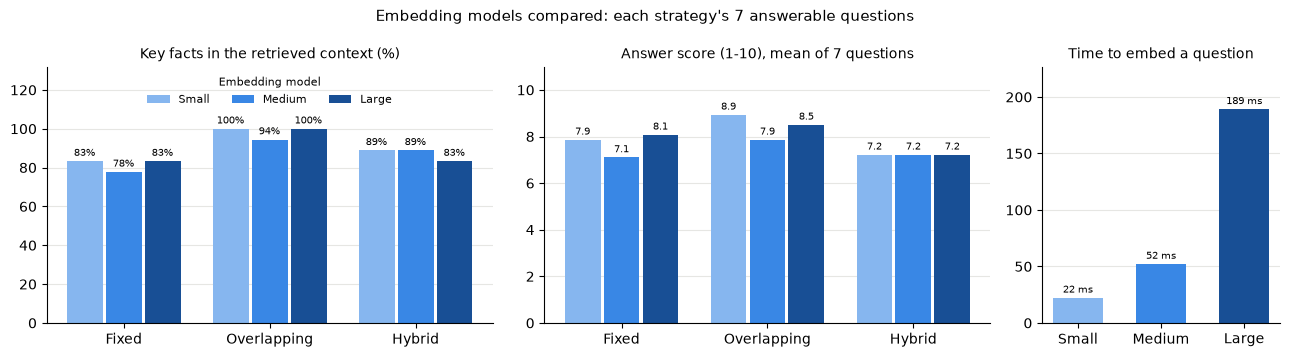

In [16]:
SIZE_COLOURS = {"Small": "#86b6ef", "Medium": "#3987e5", "Large": "#184f95"}  # one blue, light to dark: size is ordered
STRATEGY_COLOURS = {"Fixed": "#2a78d6", "Overlapping": "#eb6834", "Hybrid": "#1baf7a"}


def compare(frame, by):
    """Retrieval and answer quality per value of `by`, pooled over the answerable runs in `frame`."""
    rows = []
    for key, part in frame.groupby(by, sort=False):
        rows.append({by: key, "Facts in context": f"{part['Facts in context'].sum()}/{part['Facts'].sum()}",
                     "Facts in context (%)": 100 * part["Facts in context"].sum() / part["Facts"].sum(),
                     "Good contexts": f"{(part['Context'] == 'Good').sum()}/{len(part)}",
                     "Relevant chunks (of 3)": part["Relevant chunks"].mean(),
                     "Mean reciprocal rank": (1 / part["First relevant rank"]).mean(),
                     "Facts stated (%)": 100 * part["Facts stated"].sum() / part["Facts"].sum(),
                     "Stated, of those in context (%)": 100 * part["Facts stated"].sum() / part["Facts in context"].sum(),
                     "Answer score (1-10)": part["Answer score"].mean()})
    return pd.DataFrame(rows).set_index(by)


def grouped_bars(ax, table, groups, series, colours, fmt, title):
    """Bars for each group (x) and series (colour), each labelled with its value; one axis per panel."""
    width = 0.8 / len(series)
    for i, name in enumerate(series):
        values = [table.loc[(group, name)] for group in groups]
        bars = ax.bar(np.arange(len(groups)) + (i - (len(series) - 1) / 2) * width, values, width * 0.92,
                      label=name, color=colours[name])
        ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontsize=7.5, padding=2)
    ax.set_xticks(np.arange(len(groups)), groups)
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)


def simple_bars(ax, values, colours, fmt, title):
    bars = ax.bar(list(values.index), values.to_numpy(), 0.6, color=[colours[k] for k in values.index])
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontsize=7.5, padding=2)
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)


cost = EMBEDDING_STATS.groupby("Size", sort=False).agg(**{
    "Parameters (M)": ("Parameters (M)", "first"), "Dimensions": ("Dimensions", "first"),
    "Embed a chunk (ms, mean)": ("ms per chunk", "mean"), "Vectors, 129 chunks (KB)": ("Vectors (KB)", "sum")})
question_ms = EVALUATION.groupby("Size", sort=False)["Embed (ms)"].median().rename("Embed a question (ms, median)")
declines = EVALUATION[EVALUATION["Facts"] == 0].groupby("Size", sort=False)["Answer score"].apply(
    lambda s: f"{(s == 10).sum()}/{len(s)}").rename("Q8 declined")
BY_MODEL = cost.join(question_ms).join(compare(answerable, "Size")).join(declines)
with pd.option_context("display.max_columns", None):
    display(BY_MODEL.round(2))
BY_MODEL.to_csv(RESULTS / "by_model.csv", lineterminator="\n")
ratio = BY_MODEL.loc["Large", cost.columns.tolist() + [question_ms.name]] / BY_MODEL.loc[
    "Small", cost.columns.tolist() + [question_ms.name]]
print(f"Large against small: {ratio['Parameters (M)']:.0f} times the parameters, {ratio['Dimensions']:.1f} times the "
      f"dimensions and storage, {ratio['Embed a chunk (ms, mean)']:.1f} times the time to embed a chunk and "
      f"{ratio[question_ms.name]:.1f} times the time to embed a question, on this run.")

grid = answerable.groupby(["Strategy", "Size"], sort=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [3, 3, 1.6]})
grouped_bars(axes[0], 100 * grid["Facts in context"].sum() / grid["Facts"].sum(), list(CHUNKS), list(EMBEDDERS),
             SIZE_COLOURS, "{:.0f}%", "Key facts in the retrieved context (%)")
grouped_bars(axes[1], grid["Answer score"].mean(), list(CHUNKS), list(EMBEDDERS), SIZE_COLOURS, "{:.1f}",
             "Answer score (1-10), mean of 7 questions")
simple_bars(axes[2], question_ms, SIZE_COLOURS, "{:.0f} ms", "Time to embed a question")
axes[0].set_ylim(0, 132)
axes[1].set_ylim(0, 11)
axes[2].set_ylim(0, question_ms.max() * 1.2)
axes[0].legend(title="Embedding model", fontsize=8, title_fontsize=8, loc="upper center", ncol=3, frameon=False)
fig.suptitle("Embedding models compared: each strategy's 7 answerable questions", fontsize=11)
plt.tight_layout()
fig.savefig(RESULTS / "embedding_models.png", dpi=120)
plt.show()

In [17]:
# Did the larger model always do better? Every strategy and question, model by model (S/M/L).
pairs = answerable.pivot_table(index=["Strategy", "Q"], columns="Size", sort=False,
                               values=["Facts in context", "First relevant rank", "Answer score"])
rows = []
for (strategy, q), row in pairs.iterrows():
    found, rank, score = row["Facts in context"], row["First relevant rank"], row["Answer score"]
    smaller = ["Small", "Medium"]
    rows.append({"Strategy": strategy, "Q": q,
                 "Facts in context (S/M/L)": "/".join(f"{found[s]:.0f}" for s in EMBEDDERS),
                 "First relevant rank (S/M/L)": "/".join(f"{rank[s]:.0f}" for s in EMBEDDERS),
                 "Answer score (S/M/L)": "/".join(f"{score[s]:g}" for s in EMBEDDERS),
                 "Large found fewer facts": found["Large"] < max(found[s] for s in smaller),
                 "Large ranked evidence lower": rank["Large"] > min(rank[s] for s in smaller),
                 "Large answered worse": score["Large"] < max(score[s] for s in smaller),
                 "Large best on facts": found["Large"] > max(found[s] for s in smaller),
                 "Large best on rank": rank["Large"] < min(rank[s] for s in smaller),
                 "Large best on answer": score["Large"] > max(score[s] for s in smaller)})
LARGER_BETTER = pd.DataFrame(rows).set_index(["Strategy", "Q"])
display(LARGER_BETTER.iloc[:, :6])
worse, best = LARGER_BETTER.iloc[:, 3:6].sum(), LARGER_BETTER.iloc[:, 6:].sum()
print(f"In {len(LARGER_BETTER)} strategy-question pairs, the large model found fewer facts than a smaller model in "
      f"{worse.iloc[0]}, ranked the evidence lower in {worse.iloc[1]} and answered worse in {worse.iloc[2]}.\n"
      f"It beat both smaller models on facts found in {best.iloc[0]}, on rank in {best.iloc[1]} and on the answer "
      f"in {best.iloc[2]}.")

Facts in context (S/M/L) First relevant rank (S/M/L) Answer score (S/M/L)  Large found fewer facts  Large ranked evidence lower  Large answered worse
Strategy    Q                                                                                                                                                       
Fixed       Q1                    4/1/4                       2/2/2            10/3.2/10                    False                        False                 False
            Q2                    3/3/3                       1/1/1             10/10/10                    False                        False                 False
            Q3                    2/2/2                       1/2/2             10/10/10                    False                         True                 False
            Q4                    2/2/2                       1/1/1            5.5/10/10                    False                        False                 False
            Q5                    1/2/2                       1/1/1          5.5/5.5/5.5                    False                        False                 False
            Q6                    2/2/2                       1/1/1             10/10/10                    False                        False                 False
            Q7                    1/2/0                       3/3/6                4/1/1                     True                         True                  True
Overlapping Q1                    4/4/4                       1/1/1             10/10/10                    False                        False                 False
            Q2                    3/3/3                       2/2/2               10/7/7                    False                        False                  True
            Q3                    2/2/2                       3/2/2             10/10/10                    False                        False                 False
            Q4                    2/2/2                       1/1/1          5.5/5.5/5.5                    False                        False                 False
            Q5                    2/1/2                       1/1/1            10/5.5/10                    False                        False                 False
            Q6                    2/2/2                       1/1/1             10/10/10                    False                        False                 False
            Q7                    3/3/3                       1/1/1                7/7/7                    False                        False                 False
Hybrid      Q1                    4/4/4                       2/2/1             10/10/10                    False                        False                 False
            Q2                    3/3/3                       1/1/1                7/7/7                    False                        False                 False
            Q3                    0/0/0                       5/5/5                1/1/1                    False                        False                 False
            Q4                    2/2/1                       2/2/2          5.5/5.5/5.5                     True                        False                 False
            Q5                    2/2/2                       1/1/1             10/10/10                    False                        False                 False
            Q6                    2/2/2                       1/1/1             10/10/10                    False                        False                 False
            Q7                    3/3/3                       3/1/2                7/7/7                    False                         True                 False

In 21 strategy-question pairs, the large model found fewer facts than a smaller model in 2, ranked the evidence lower in 3 and answered worse in 2.
It beat both smaller models on facts found in 0, on rank in 1 and on the answer in 0.


**How does embedding size affect retrieval quality?** On this handbook, hardly at all, and not in the order of
size. Pooled over the three strategies, the small model put 49 of the 54 key facts into the context (91%), the large
model 48 (89%) and the medium model 47 (87%), and the first relevant chunk ranked about as high for all three (mean
reciprocal rank 0.77 to 0.79). Each gap comes from one or two questions where a needed chunk ranked just below the
top 3:

* the medium model missed Q1's seat counts with fixed chunks (the chunk holding them ranked 4th) and Q5's "only
  totals" with overlapping chunks (4th);
* the large model missed all three facts of Q7 with fixed chunks (its best evidence chunk ranked 6th) and Q4's group
  size with hybrid chunks (4th);
* the small model missed Q5's "only totals" with fixed chunks (4th).

The differences are this small because the task is easy for all three. The handbook is short (31 to 50 chunks per
strategy) and written in plain words, and each question is about a subject the handbook names. The three models
also come from one family and were trained the same way, so they mostly agree on which chunks are closest.

**How does embedding size affect answer quality?** Answers follow the context, so they barely depend on the model
either: 8.0 out of 10 for the small model, 7.9 for the large and 7.4 for the medium. Against the small model, the
medium model lost points in four runs and gained in one. Two were lost in retrieval (Q1 and Q5 above) and two by the
generator: it left out a fact that was in the context (Q2 with overlapping chunks), and for Q7 with fixed chunks it
answered that the excerpts do not cover the question, although they held two of its three facts. The gain was Q4
with fixed chunks, where the medium model's answer also named the group size. Most lost points are the generator's, not the retriever's: of the facts
that reached the context, the answers stated 88% with the small and the large model and 81% with the medium. The
generator tends to give the main point and drop a second fact, such as Q2's "QuadConnect cannot send a reset link"
or Q7's outside services. The noise around the evidence matters too. For Q2 with overlapping chunks, all three
models retrieved the same two chunks first and a different third chunk, and only the small model's answer stated all
three facts.

**Did larger embeddings always perform better?** No. In the 21 strategy-question pairs above, the large model found
fewer facts than a smaller model in 2, ranked the evidence lower in 3 and answered worse in 2. It beat both smaller
models only once, with a better rank for Q1 on hybrid chunks, and never on facts found or on the answer. It cost far
more: 10 times the small model's parameters, 2.7 times the storage per vector, about 10 times the time to embed a
chunk and several times the time to embed a question (this run's ratios are printed above; timings vary from run to
run). **For a knowledge base of this size, the small model is the better choice:** it did at least as well, for a
fraction of the cost. A larger model is worth testing again when the
collection grows or the questions get harder to match, which is what Step 2.5 starts to do.

## Step 2.4: Compare chunking strategies

The same 63 runs, grouped by chunking strategy: each strategy pools its three models (21 runs, 54 key facts). The
cost side is how much the generator reads: words per chunk, words in the context, and prompt tokens.

,Words per chunk,Context words (mean),Noise words (mean),Prompt tokens (mean),"Generate (s, median)",Facts in context,Facts in context (%),Good contexts,Relevant chunks (of 3),Mean reciprocal rank,Facts stated (%),"Stated, of those in context (%)",Answer score (1-10),Q8 declined
Strategy,,,,,,,,,,,,,,
Fixed,97.50,298.71,128.33,548.17,0.92,44/54,81.48,16/21,1.67,0.78,72.22,88.64,7.68,3/3
Overlapping,222.16,678.86,286.29,991.54,0.86,53/54,98.15,20/21,1.76,0.85,83.33,84.91,8.43,3/3
Hybrid,101.56,310.62,169.95,553.67,0.72,47/54,87.04,17/21,1.38,0.71,72.22,82.98,7.21,3/3


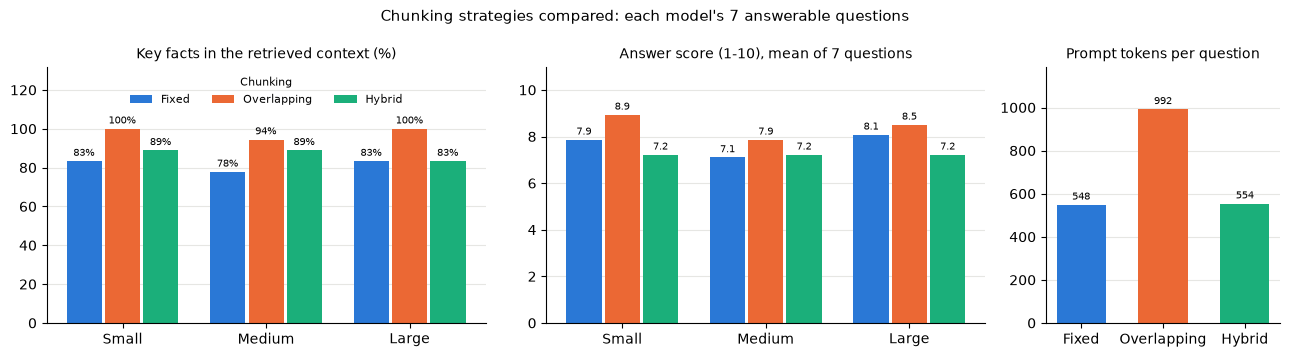

Per question, summed over the three models (facts) and averaged (answer score):


Facts Facts in context                    Answer score                   
Strategy x 3 models            Fixed Overlapping Hybrid        Fixed Overlapping Hybrid
Q                                                                                      
Q1               36                9          12     12         7.73        10.0   10.0
Q2               27                9           9      9        10.00         8.0    7.0
Q3               18                6           6      0        10.00        10.0    1.0
Q4               18                6           6      5         8.50         5.5    5.5
Q5               18                5           5      6         5.50         8.5   10.0
Q6               18                6           6      6        10.00        10.0   10.0
Q7               27                3           9      9         2.00         7.0    7.0

Mean answer score without Q3: Fixed 7.29, Overlapping 8.17, Hybrid 8.25


In [18]:
for i in range(1, TOP_K + 1):  # words of each retrieved chunk, to measure how much of the context is noise
    EVALUATION[f"Chunk {i} words"] = EVALUATION[f"Chunk {i} text"].str.split().str.len()
EVALUATION["Context words"] = sum(EVALUATION[f"Chunk {i} words"] for i in range(1, TOP_K + 1))
EVALUATION["Noise words"] = sum(EVALUATION[f"Chunk {i} words"] * ~EVALUATION[f"Chunk {i} relevant"]
                                for i in range(1, TOP_K + 1))
answerable = EVALUATION[EVALUATION["Facts"] > 0]
reading = answerable.groupby("Strategy", sort=False).agg(**{
    "Words per chunk": ("Strategy", lambda s: CHUNKS[s.iloc[0]]["Words"].mean()),
    "Context words (mean)": ("Context words", "mean"), "Noise words (mean)": ("Noise words", "mean")})
tokens = EVALUATION.groupby("Strategy", sort=False).agg(**{
    "Prompt tokens (mean)": ("Prompt tokens", "mean"), "Generate (s, median)": ("Generate (s)", "median")})
declines = EVALUATION[EVALUATION["Facts"] == 0].groupby("Strategy", sort=False)["Answer score"].apply(
    lambda s: f"{(s == 10).sum()}/{len(s)}").rename("Q8 declined")
BY_STRATEGY = reading.join(tokens).join(compare(answerable, "Strategy")).join(declines)
with pd.option_context("display.max_columns", None):
    display(BY_STRATEGY.round(2))
BY_STRATEGY.to_csv(RESULTS / "by_strategy.csv", lineterminator="\n")

grid = answerable.groupby(["Size", "Strategy"], sort=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [3, 3, 1.6]})
grouped_bars(axes[0], 100 * grid["Facts in context"].sum() / grid["Facts"].sum(), list(EMBEDDERS), list(CHUNKS),
             STRATEGY_COLOURS, "{:.0f}%", "Key facts in the retrieved context (%)")
grouped_bars(axes[1], grid["Answer score"].mean(), list(EMBEDDERS), list(CHUNKS), STRATEGY_COLOURS, "{:.1f}",
             "Answer score (1-10), mean of 7 questions")
simple_bars(axes[2], BY_STRATEGY["Prompt tokens (mean)"], STRATEGY_COLOURS, "{:.0f}", "Prompt tokens per question")
axes[0].set_ylim(0, 132)
axes[1].set_ylim(0, 11)
axes[2].set_ylim(0, BY_STRATEGY["Prompt tokens (mean)"].max() * 1.2)
axes[0].legend(title="Chunking", fontsize=8, title_fontsize=8, loc="upper center", ncol=3, frameon=False)
fig.suptitle("Chunking strategies compared: each model's 7 answerable questions", fontsize=11)
plt.tight_layout()
fig.savefig(RESULTS / "chunking_strategies.png", dpi=120)
plt.show()

per_question = answerable.pivot_table(index="Q", columns="Strategy", values=["Facts in context", "Answer score"],
                                      aggfunc={"Facts in context": "sum", "Answer score": "mean"}, sort=False)
per_question.insert(0, ("Facts", "x 3 models"), answerable.groupby("Q", sort=False)["Facts"].sum())
print("Per question, summed over the three models (facts) and averaged (answer score):")
display(per_question.round(2))
without_q3 = answerable[answerable["Q"] != "Q3"].groupby("Strategy", sort=False)["Answer score"].mean()
print("Mean answer score without Q3: " + ", ".join(f"{s} {v:.2f}" for s, v in without_q3.items()))

In [19]:
import textwrap


def wrapped(text, indent="      "):
    return "\n".join(textwrap.fill(line, 116, initial_indent=indent, subsequent_indent=indent)
                     for line in text.splitlines() if line.strip())


example = EVALUATION[(EVALUATION["Q"] == "Q1") & (EVALUATION["Size"] == "Medium")]
print(f"What the generator saw for Q1, '{TESTS[0]['Query']}', with the medium model under each strategy.\n"
      "The evidence is the seat counts and the sentence 'A full squad of eight therefore fits every venue except "
      "Espresso Royale', both in paragraph S06-P2.\n")
for _, row in example.iterrows():
    print(f"=== {row['Strategy']}: {row['Retrieved Context Quality']}. Answer {row['Answer Quality']}.")
    for i in range(1, TOP_K + 1):
        label = "relevant" if row[f"Chunk {i} relevant"] else "noise"
        print(f"  [{i}] {row[f'Chunk {i}']}, {label}, score {row[f'Chunk {i} score']:.3f}")
        print(wrapped(row[f"Chunk {i} text"]))
    print(f"  Answer:\n{wrapped(row['Answer'])}\n")

What the generator saw for Q1, 'Our squad has eight people. Which venues have enough seats for all of us?', with the medium model under each strategy.
The evidence is the seat counts and the sentence 'A full squad of eight therefore fits every venue except Espresso Royale', both in paragraph S06-P2.

=== Fixed: Partial: 1/4 facts; 1/3 chunks relevant. Answer 3.2/10: 1/4 facts stated.
  [1] fix-20, noise, score 0.667
      This matters most in a squad, where several people plan their weekend around the group. A clear decline lets
      the others know who is coming, while a silent no-show leaves them waiting at the venue and wondering whether
      the meetup is still on. Squad matches bring four to eight students together, so they need more planning than a
      one-on-one coffee. Every venue records the largest group it can seat comfortably, from 2 to 50 people, so that
      a squad is planned for a place that fits it. A squad is also a good setting for the suggested activity,
      

**Which chunking strategy worked better?** Overlapping paragraphs, on every measure of quality. They put 53 of the
54 key facts into the context (98%), gave 20 Good contexts out of 21, ranked the first relevant chunk highest (mean
reciprocal rank 0.85), and led to the best answers (8.4 out of 10). Hybrid chunks retrieved 47 facts (87%) and
scored 7.2; fixed-length chunks retrieved the fewest, 44 (81%), and scored 7.7.

**Why:**

* **Overlapping gives every paragraph two chances, and keeps it whole.** Apart from the first and last paragraph of
  a section, each paragraph sits in two chunks, so if one pairing ranks low, the other can still reach the top 3.
  And no paragraph is ever cut: Q1's seat counts and its conclusion, "a full squad of eight therefore fits every
  venue except Espresso Royale", always arrive together.
* **Fixed length cuts where the word count says, not where the meaning does.** The 120-word limit put those two
  sentences of Q1 into different chunks (above). The medium model retrieved only the second, so its answer could say
  "all venues except Espresso Royale" but could not name a single venue, and it scored 3.2.
* **Hybrid chunks are precise, but each paragraph has only one chance, and every chunk starts with its section's
  title.** Q3, "Why didn't I get a match this week?", failed on hybrid chunks with all three models: the top 3 were
  all chunks of Section 5, *How weekly matching works*, which share the question's words (match, week), while the
  evidence ranked 5th. With fixed and overlapping chunks, Section 5 still took one or two of the top places, but
  at least one chunk holding the evidence reached the top 3 for every model. Part 3 tests whether the titles cause
  this.

**How did chunking affect retrieval relevance?** It decided whether the evidence was found at all (Q1 with fixed
chunks, Q3 with hybrid chunks), and how much noise came with it. The count of relevant chunks favours overlapping
(1.76 of 3, against 1.67 for fixed and 1.38 for hybrid), but partly by construction: a paragraph is in two
overlapping chunks and only one hybrid chunk, so when the answer is in one paragraph, as for Q1 and Q2, two of
hybrid's three chunks are noise however well it ranks. Measured in words, the trade runs the other way: an
overlapping context averages about 680 words, of which about 290 are noise, against about 310 words with 170 of noise
for hybrid and 300 with 130 for fixed length.

**How did chunking affect the final answers?** Answers followed the context. Overlapping, with the most complete
context, gave the best answers, and it was the only strategy with no Poor context. Hybrid's lower mean comes almost
entirely from Q3: without Q3, hybrid's answers average 8.25 and overlapping's 8.17, so on the other six questions
hybrid matched overlapping with prompts about 45% smaller (550 tokens against 990). Bigger chunks cost more input
tokens, but on Groq they barely changed how long an answer took (median 0.7 to 0.9 seconds for every strategy).

**In short:** overlapping chunks are the most reliable here, at almost twice the prompt size; hybrid chunks are as
good on most questions at half the size, but one wording made them miss; fixed-length chunks are the weakest,
because they ignore the handbook's structure.

## Step 2.5: Data scaling experiment

The same eight questions run on three datasets, each one containing the one before it:

| Dataset | What it holds | Paragraphs | Words | Overlapping chunks |
|---|---|---|---|---|
| Small | Sections 1 to 7 of the handbook: the account, the profile, availability, matching, meeting up and venues | 25 | 2,958 | 18 |
| Full | The whole handbook, as in Steps 2.1 to 2.4 | 44 | 4,875 | 31 |
| Large | The handbook plus QuadConnect's staff and developer guide, `data/staff_guide.md` | 88 | 9,430 | 64 |

**The small dataset** is the handbook as if only its first seven sections had been written. It still holds 14 of the
18 key facts. Q5's evidence and two of Q7's three facts are in the later sections, so these two questions show what a
smaller dataset does to a question it no longer covers.

**The large dataset** adds a second document of 44 paragraphs (4,555 words), written for this experiment from
QuadConnect's code in the same way as the handbook. It is about running the app rather than using it: the settings,
the admin site, how the venue check works inside, the data model, the tests and the deployment. It uses the
handbook's vocabulary (venues, matches, feedback, Google, Groq) but is not written for students, which makes it
realistic noise: text that looks related to a student's question but rarely answers it. Where a guide sentence does
state a key fact, as "Staff make the final decision" does for Q6, it counts as evidence, so a guide chunk is noise
only when it holds none of the question's facts. Those sentences were listed before the experiment ran
(`GUIDE_EVIDENCE` below).

**The setup:** overlapping chunks, the strategy that retrieved best in Step 2.4, with all three embedding models, k = 3
and the same generator. The datasets differ by whole sections, so every chunk of a smaller dataset is also a chunk of
the larger ones, with the same text. Any change in the top 3 therefore comes from chunks that were added or removed.

**Measures:** facts in the dataset and in the context, and the answer score, as in Step 2.2; noise, the number of the
three retrieved chunks that hold no evidence; and the margin, how much higher the best relevant chunk scores than the
best noise chunk. A shrinking margin means noise is closing in on the evidence, even before it pushes the evidence
out; a negative margin means a noise chunk already ranks above all of the evidence (which may still be in the top 3).
The noise measures use the five questions whose evidence is in all three datasets, Q1, Q2, Q3, Q4 and Q6, so
that lost coverage and added noise are not mixed up.

In [20]:
guide = read_handbook(DATA / "staff_guide.md")
guide["Paragraph"] = "G" + guide["Paragraph"].str[1:]  # G01-P1: the guide's paragraphs, apart from the handbook's
guide["Sentences"] = guide["Text"].map(sentences)
SCALE_STRATEGY = "Overlapping"  # the strategy that retrieved best in Step 2.4
require(BY_STRATEGY["Facts in context (%)"].idxmax() == SCALE_STRATEGY, "Step 2.4's best strategy has changed")
chunker = {"Fixed": fixed_length, "Overlapping": overlapping, "Hybrid": hybrid}[SCALE_STRATEGY]
DATASETS = {"Small": handbook[handbook["Section"].str.split(".").str[0].astype(int) <= 7],
            "Full": handbook, "Large": pd.concat([handbook, guide], ignore_index=True)}

# Guide sentences that state one of the key facts: a guide chunk that holds one is relevant, not noise.
GUIDE_EVIDENCE = {
    ("Q2", "no reset email"): [("the login form leaves out the usual link for a forgotten password, because the "
                                "app sends no email")],
    ("Q5", "never shown"): ["The notes are never shown to the other students in a match"],
    ("Q6", "only advises"): ["Judge the venue yourself, using the check only as advice",
                             "it never touches the approval field, which only staff change"],
    ("Q6", "staff decide"): ["will be listed once staff approve it", "Staff make the final decision",
                             "Judge the venue yourself, using the check only as advice", "which only staff change"],
    ("Q7", "only counts public"): [("Only /api/summary/ is public, and any website may read it, because it holds "
                                    "counts and no personal data.")],
    ("Q7", "outside services"): ["The student who suggested it is never included",
                                 "It then replaces email addresses with [email]",
                                 "The live site runs on PythonAnywhere's free plan"],
}
for (q, key), extra in GUIDE_EVIDENCE.items():
    require(any(f["Key"] == key for t in TESTS if t["Q"] == q for f in t["Facts"]), f"no fact {key!r} in {q}")
    for e in extra:
        require(any(e in text for text in guide["Text"]), f"guide evidence not found: {e}")
SCALE_TESTS = [{**t, "Facts": [{**f, "Evidence": f["Evidence"] + GUIDE_EVIDENCE.get((t["Q"], f["Key"]), [])}
                               for f in t["Facts"]]} for t in TESTS]

SCALE_CHUNKS, rows = {}, []
for name, book in DATASETS.items():
    SCALE_CHUNKS[name] = chunks = chunker(book)
    present = sum(any(e in body for body in chunks["Body"] for e in f["Evidence"]) for t in SCALE_TESTS
                  for f in t["Facts"])
    rows.append({"Dataset": name, "Paragraphs": len(book), "Words": book["Words"].sum(), "Chunks": len(chunks),
                 "Handbook sections": book.loc[book["Paragraph"].str.startswith("S"), "Section"].nunique(),
                 "Guide sections": book.loc[book["Paragraph"].str.startswith("G"), "Section"].nunique(),
                 "Key facts the dataset contains": f"{present}/{N_FACTS}"})
display(pd.DataFrame(rows).set_index("Dataset"))

,Paragraphs,Words,Chunks,Handbook sections,Guide sections,Key facts the dataset contains
Dataset,,,,,,
Small,25,2958,18,7,0,14/18
Full,44,4875,31,13,0,18/18
Large,88,9430,64,13,11,18/18


In [21]:
SCALE_STORES = {(name, size): STORES[size, SCALE_STRATEGY] if name == "Full" else VectorStore(MODELS[size], chunks)
                for name, chunks in SCALE_CHUNKS.items() for size in EMBEDDERS}
longest = max(len(MODELS[size].tokenizer(text)["input_ids"]) for size in EMBEDDERS
              for text in SCALE_CHUNKS["Large"]["Text"])
require(longest <= 512, "a chunk of the large dataset would be cut off")


def scale_run(name, size, test):
    """One question on one dataset and model: facts found, noise, how close the nearest noise came, the answer."""
    store, facts = SCALE_STORES[name, size], test["Facts"]
    ranking = store.search(store.embed_query(test["Query"]), k=len(store.chunks))
    holds = [[any(e in body for e in f["Evidence"]) for f in facts] for body in ranking["Body"]]
    relevant = pd.Series([any(row) for row in holds], index=ranking.index)
    top = ranking.head(TOP_K)
    reply = generate(build_messages(test["Query"], top))
    require(reply.get("answer") is not None, f"no saved answer for {test['Q']} on {name}/{size}: set GROQ_API_KEY")
    stated, declined, invented, score = score_answer(test, reply["answer"])
    return {"Dataset": name, "Size": size, "Q": test["Q"], "Facts": len(facts),
            "Facts in dataset": sum(any(row[i] for row in holds) for i in range(len(facts))),
            "Facts in context": sum(any(row[i] for row in holds[:TOP_K]) for i in range(len(facts))),
            "Noise chunks": int((~relevant.head(TOP_K)).sum()),
            "Guide chunks": int(top["Paragraphs"].map(lambda ps: ps[0].startswith("G")).sum()),
            "First relevant rank": next((r for r, rel in enumerate(relevant, start=1) if rel), None),
            "Best relevant score": ranking.loc[relevant, "Score"].max() if relevant.any() else None,
            "Best noise score": ranking.loc[~relevant, "Score"].max(),
            "Nearest noise": "{} ({})".format(*ranking.loc[~relevant].iloc[0][["Chunk", "Paragraphs"]].pipe(
                lambda r: (r["Chunk"], " ".join(r["Paragraphs"])))),
            "Retrieved": ", ".join(f"{c} ({' '.join(ps)})" for c, ps in zip(top["Chunk"], top["Paragraphs"],
                                                                            strict=True)),
            "Answer score": score, "Facts stated": sum(stated), "Declined": declined, "Answer": reply["answer"]}


saved_before = len(CACHE)
SCALING = pd.DataFrame([scale_run(name, size, test) for name in DATASETS for size in EMBEDDERS
                        for test in SCALE_TESTS])
SCALING["Margin"] = SCALING["Best relevant score"] - SCALING["Best noise score"]
SCALING.to_csv(RESULTS / "scaling.csv", index=False, lineterminator="\n")
print(f"{len(SCALING)} runs (3 datasets x 3 models x 8 questions); {len(CACHE) - saved_before} answers generated "
      "now, the rest reused. Saved to results/scaling.csv")

answerable_scale = SCALING[SCALING["Facts"] > 0]
covered = answerable_scale.groupby("Q", sort=False).apply(lambda g: (g["Facts in dataset"] == g["Facts"]).all())
SHARED = list(covered[covered].index)  # questions whose every fact is in all three datasets: the pure noise effect
shared = answerable_scale[answerable_scale["Q"].isin(SHARED)]
n_shared = sum(len(t["Facts"]) for t in SCALE_TESTS if t["Q"] in SHARED)
whole = answerable_scale.groupby(["Dataset", "Size"], sort=False)
part = shared.groupby(["Dataset", "Size"], sort=False)
q8 = SCALING[SCALING["Facts"] == 0].set_index(["Dataset", "Size"])
SCALE_SUMMARY = pd.DataFrame({
    f"Facts in the dataset (of {N_FACTS})": whole["Facts in dataset"].sum(),
    f"Facts in context (of {N_FACTS})": whole["Facts in context"].sum(),
    "Answer score (7 questions)": whole["Answer score"].mean(),
    f"Facts in context (of {n_shared}, shared)": part["Facts in context"].sum(),
    "Noise chunks (of 3, shared)": part["Noise chunks"].mean(),
    "Guide chunks (of 3, shared)": part["Guide chunks"].mean(),
    "Margin over the nearest noise (shared)": part["Margin"].mean(),
    "Q8 declined": q8["Answer score"].eq(10).map({True: "yes", False: "no"}),
    "Q8 top score": q8["Best noise score"]})
print(f"'Shared' = the {len(SHARED)} questions whose evidence is in all three datasets ({', '.join(SHARED)}): "
      "on these, any change comes from noise alone.")
with pd.option_context("display.max_columns", None):
    display(SCALE_SUMMARY.round(3))
SCALE_SUMMARY.to_csv(RESULTS / "scaling_summary.csv", lineterminator="\n")

72 runs (3 datasets x 3 models x 8 questions); 0 answers generated now, the rest reused. Saved to results/scaling.csv
'Shared' = the 5 questions whose evidence is in all three datasets (Q1, Q2, Q3, Q4, Q6): on these, any change comes from noise alone.


Facts in the dataset (of 18)  Facts in context (of 18)  Answer score (7 questions)  Facts in context (of 13, shared)  Noise chunks (of 3, shared)  Guide chunks (of 3, shared)  \
Dataset Size                                                                                                                                                                                     
Small   Small                             14                        13                       6.357                                13                          1.4                          0.0   
        Medium                            14                        13                       6.357                                13                          1.4                          0.0   
        Large                             14                        13                       6.357                                13                          1.2                          0.0   
Full    Small                             18                        18                       8.929                                13                          1.4                          0.0   
        Medium                            18                        17                       7.857                                13                          1.2                          0.0   
        Large                             18                        18                       8.500                                13                          1.2                          0.0   
Large   Small                             18                        18                       8.500                                13                          1.2                          0.2   
        Medium                            18                        17                       8.286                                13                          1.0                          0.2   
        Large                             18                        18                       8.500                                13                          1.0                          0.4   

                Margin over the nearest noise (shared) Q8 declined  Q8 top score  
Dataset Size                                                                      
Small   Small                                    0.049         yes         0.722  
        Medium                                   0.038         yes         0.712  
        Large                                    0.039         yes         0.758  
Full    Small                                    0.035         yes         0.722  
        Medium                                   0.031         yes         0.712  
        Large                                    0.037         yes         0.758  
Large   Small                                    0.017         yes         0.722  
        Medium                                   0.012         yes         0.712  
        Large                                    0.011         yes         0.758

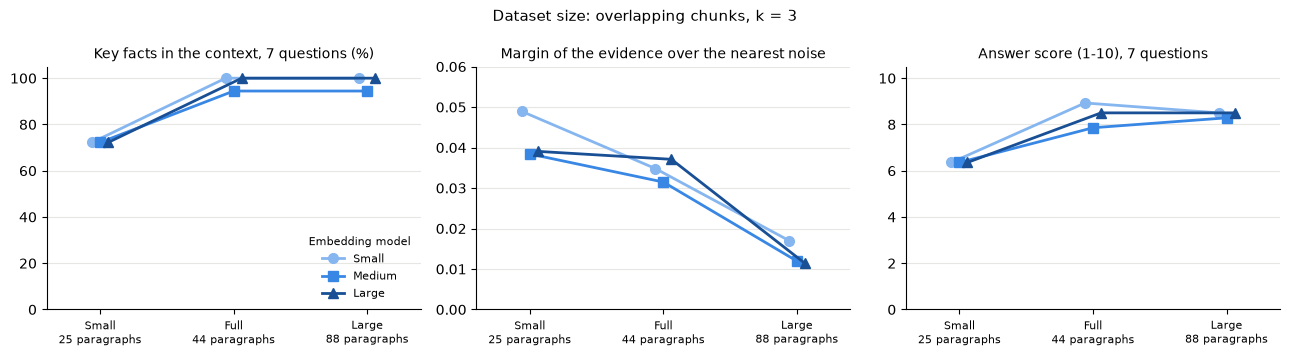

24 of 48 runs on the small and large datasets retrieved a different top 3 from the full handbook:


Facts  Facts in dataset  Facts in context on Full  Facts in context  Guide chunks  Answer score on Full  Answer score  \
Dataset Size   Q                                                                                                                           
Small   Small  Q2      3                 3                         3                 3             0                  10.0           7.0   
               Q3      2                 2                         2                 2             0                  10.0          10.0   
               Q4      2                 2                         2                 2             0                   5.5           5.5   
               Q5      2                 0                         2                 0             0                  10.0           1.0   
               Q6      2                 2                         2                 2             0                  10.0          10.0   
               Q7      3                 1                         3                 0             0                   7.0           1.0   
               Q8      0                 0                         0                 0             0                  10.0          10.0   
        Medium Q2      3                 3                         3                 3             0                   7.0           7.0   
               Q3      2                 2                         2                 2             0                  10.0           5.5   
               Q4      2                 2                         2                 2             0                   5.5          10.0   
               Q5      2                 0                         1                 0             0                   5.5           1.0   
               Q6      2                 2                         2                 2             0                  10.0          10.0   
               Q7      3                 1                         3                 0             0                   7.0           1.0   
        Large  Q3      2                 2                         2                 2             0                  10.0          10.0   
               Q4      2                 2                         2                 2             0                   5.5           5.5   
               Q5      2                 0                         2                 0             0                  10.0           1.0   
               Q6      2                 2                         2                 2             0                  10.0          10.0   
               Q7      3                 1                         3                 0             0                   7.0           1.0   
               Q8      0                 0                         0                 0             0                  10.0          10.0   
Large   Small  Q2      3                 3                         3                 3             1                  10.0           7.0   
        Medium Q2      3                 3                         3                 3             1                   7.0          10.0   
        Large  Q2      3                 3                         3                 3             1                   7.0           7.0   
               Q5      2                 2                         2                 2             1                  10.0          10.0   
               Q6      2                 2                         2                 2             1                  10.0          10.0   

                                                                        Retrieved on Full                                                               Retrieved  
Dataset Size   Q                                                                                                                                                   
Small   Small  Q2  ove-03 (S02-P1 S02-P2), ove-04 

In [22]:
paragraphs = {name: len(book) for name, book in DATASETS.items()}
MARKERS = {"Small": "o", "Medium": "s", "Large": "^"}  # a shape per model, so overlapping lines stay readable
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [(f"Facts in context (of {N_FACTS})", 100 / N_FACTS, "Key facts in the context, 7 questions (%)", 105),
          ("Margin over the nearest noise (shared)", 1, "Margin of the evidence over the nearest noise", 0.06),
          ("Answer score (7 questions)", 1, "Answer score (1-10), 7 questions", 10.5)]
for ax, (column, scale, title, top) in zip(axes, panels, strict=True):
    for offset, size in zip((-0.06, 0, 0.06), EMBEDDERS, strict=True):
        values = SCALE_SUMMARY.xs(size, level="Size")[column] * scale
        ax.plot(np.arange(len(values)) + offset, values.to_numpy(), marker=MARKERS[size], markersize=7,
                linewidth=2, color=SIZE_COLOURS[size], label=size)
    ax.set_xticks(range(len(paragraphs)), [f"{name}\n{n} paragraphs" for name, n in paragraphs.items()], fontsize=8)
    ax.set_xlim(-0.4, len(paragraphs) - 0.6)
    ax.set_ylim(0, top)
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].legend(title="Embedding model", fontsize=8, title_fontsize=8, loc="lower right", frameon=False)
fig.suptitle(f"Dataset size: {SCALE_STRATEGY.lower()} chunks, k = 3", fontsize=11)
plt.tight_layout()
fig.savefig(RESULTS / "dataset_size.png", dpi=120)
plt.show()

# Every run whose top 3 differs from the full handbook's, for the same model and question.
full = SCALING[SCALING["Dataset"] == "Full"].set_index(["Size", "Q"])
changed = SCALING[(SCALING["Dataset"] != "Full") & SCALING.apply(
    lambda r: r["Retrieved"] != full.loc[(r["Size"], r["Q"]), "Retrieved"], axis=1)].copy()
for column in ["Facts in context", "Answer score", "Retrieved"]:
    changed[f"{column} on Full"] = changed.apply(lambda r, c=column: full.loc[(r["Size"], r["Q"]), c], axis=1)
CHANGES = changed[["Dataset", "Size", "Q", "Facts", "Facts in dataset", "Facts in context on Full", "Facts in context",
                   "Guide chunks", "Answer score on Full", "Answer score", "Retrieved on Full", "Retrieved"]]
print(f"{len(CHANGES)} of {len(SCALING) - len(full)} runs on the small and large datasets retrieved a different top 3 "
      "from the full handbook:")
with pd.option_context("display.max_colwidth", None):
    display(CHANGES.set_index(["Dataset", "Size", "Q"]))

**How does dataset size affect retrieval quality?**

* **A smaller dataset loses coverage, not precision.** The small dataset holds only 14 of the 18 key facts, so every
  model's context held 13, against 17 or 18 on the full handbook, and the answer score fell from 7.9–8.9 to 6.4. All
  of that loss is coverage. On the five questions whose evidence it still holds, every model retrieved all 13 of
  their facts, exactly as on the full handbook. For Q5 and Q7, which lost all or most of their evidence, all six runs
  answered that the handbook does not cover the question rather than guessing: the system lost answers but stayed
  honest.
* **A larger dataset kept the same facts in the context.** On the large dataset the facts in the context did not
  change (18, 17 and 18 of 18, as on the full handbook), and the answer scores stayed within half a point (8.3 to
  8.5), moved only by different wording in Q2's answers. Five guide chunks reached a top 3 (Q2 with all three
  models, and Q5 and Q6 with the large model), and every one of them held a key fact: the guide restates a few of
  the handbook's facts for staff, so more data also brought more evidence. On the five shared questions, noise in the
  top 3 even fell slightly, from 1.2–1.4 chunks to 1.0–1.2, because those guide chunks replaced handbook noise.

**How does dataset size affect noise?**

* **Noise moves closer as the dataset grows.** On the five shared questions, the margin of the evidence over the
  nearest noise chunk averaged 0.038 to 0.049 on the small dataset, 0.031 to 0.037 on the full handbook and 0.011 to
  0.017 on the large one: doubling the data cut it to between a third and a half. Most of the drop is Q6. On the full
  handbook its evidence led every noise chunk by 0.14 to 0.16. On the large dataset the nearest noise was the guide's
  two paragraphs on how the venue check works (ove-47, G06-P1 and G06-P2), which describe the same AI check but not
  who approves a venue, and they came within 0.035 to 0.05.
* **At k = 3 the noise did not yet push evidence out,** but a margin of about 0.01 leaves little room: a slightly
  different wording, or a still larger collection, would let near-misses through. As a knowledge base grows,
  retrieval has to separate the right chunk from more and more similar text.
* **A smaller dataset has wider margins on what it covers, and nothing but noise on what it does not.** For Q5 and
  Q7 on the small dataset, all three retrieved chunks were noise, so the generator's refusal was the only safeguard.
* **A question that nothing answers is unaffected.** Q8 drew the same top score on all three datasets (0.71 to
  0.76): the guide added nothing closer to "Do I have to pay?" than the handbook had, and every run declined.

**In short:** a smaller dataset fails by missing information, and a larger one by crowding the right chunk with
near-misses. The second effect grows with scale, which is why Part 4 returns to it.

### Part 2 at a glance

| Step | What was done | Main result |
|---|---|---|
| 2.1 Test queries | 8 questions in a student's words; 18 key facts with the sentences that state them; one question the handbook does not answer | The evidence spans 17 paragraphs in 10 sections |
| 2.2 Evaluation table | 72 runs (9 configurations × 8 questions), each with its retrieved chunks, context quality, answer score, latency and notes | Best: the small model with overlapping chunks (18 of 18 facts retrieved, answers 8.9 of 10); every configuration declined Q8 |
| 2.3 Embedding models | Model size against retrieval, answers and cost | The small model did as well as the large one at a fraction of the cost: larger was not always better |
| 2.4 Chunking strategies | Fixed length, overlapping and hybrid compared | Overlapping retrieved 98% of the facts and gave the best answers; leaving out Q3, which hybrid missed, hybrid's answers averaged as high at about half the prompt size |
| 2.5 Dataset size | Small (25 paragraphs), full (44) and large (88) datasets | A smaller dataset loses coverage; a larger one kept the facts, but the evidence's lead over the nearest noise shrank to a third or a half |

# Part 3: Failure analysis and improvement

Every failure below happened in Part 2's 72 runs; none was staged for this part. Step 3.1 counts where the key facts
were lost and shows four failures in detail. Step 3.2 tests each failure's possible causes one at a time. Step 3.3
fixes the two main causes and measures the system before and after.

## Step 3.1: Failure cases

A key fact can be lost in two places: in **retrieval**, when it never reaches the context, or in **generation**, when
it is in the context but the answer leaves it out. Counting every key fact of every run (18 facts × 9 configurations
= 162) shows where the system loses information.

In [23]:
fact_rows = []
for _, run in EVALUATION.iterrows():
    test = next(t for t in TESTS if t["Q"] == run["Q"])
    texts = [run[f"Chunk {i} text"] for i in range(1, TOP_K + 1)]
    answer = run["Answer"].translate(PLAIN)
    for f in test["Facts"]:
        fact_rows.append({"Q": run["Q"], "Size": run["Size"], "Strategy": run["Strategy"], "Fact": f["Key"],
                          "In context": any(e in text for text in texts for e in f["Evidence"]),
                          "Stated": bool(re.search(f["Pattern"], answer, re.I))})
FACTS = pd.DataFrame(fact_rows)
FACTS["Outcome"] = np.select(
    [FACTS["In context"] & FACTS["Stated"], FACTS["In context"], FACTS["Stated"]],
    ["Stated", "Lost by the generator", "Stated without its evidence"], "Lost in retrieval")
OUTCOMES = ["Stated", "Lost in retrieval", "Lost by the generator", "Stated without its evidence"]
census = FACTS.pivot_table(index="Strategy", columns="Outcome", aggfunc="size", fill_value=0, sort=False)
census = census.reindex(columns=OUTCOMES, fill_value=0)
census.loc["All nine configurations"] = census.sum()
display(census)
by_fact = FACTS.pivot_table(index=["Q", "Fact"], columns="Outcome", aggfunc="size", fill_value=0, sort=False)
by_fact = by_fact.reindex(columns=OUTCOMES, fill_value=0)
print("The facts that were lost, and where (out of 9 runs each):")
display(by_fact[(by_fact["Lost in retrieval"] + by_fact["Lost by the generator"]) > 0])

Outcome,Stated,Lost in retrieval,Lost by the generator,Stated without its evidence
Strategy,,,,
Fixed,39,10,5,0
Overlapping,45,1,8,0
Hybrid,39,7,8,0
All nine configurations,123,18,21,0


The facts that were lost, and where (out of 9 runs each):


Outcome                Stated  Lost in retrieval  Lost by the generator  Stated without its evidence
Q  Fact                                                                                             
Q1 Illini Union             8                  1                      0                            0
   Grainger                 8                  1                      0                            0
   Main Quad                8                  1                      0                            0
Q2 no reset email           4                  0                      5                            0
Q3 shared slot needed       6                  3                      0                            0
   mark more windows        6                  3                      0                            0
Q4 group size               2                  1                      6                            0
Q5 only totals              5                  2                      2                            0
Q7 not sold                 7                  2                      0                            0
   only counts public       6                  2                      1                            0
   outside services         0                  2                      7                            0

**Both halves of the system lose facts.** Retrieval lost 18 of the 162 key facts, and the generator lost 21 more that
were in the context. No answer stated a key fact without its evidence, so no fact was guessed.

**Four failures, one of each kind the brief names and one more:**

| | Failure | Kind | Where it happened |
|---|---|---|---|
| F1 | Q3's evidence never reached the context, so the answer said the handbook does not explain it | Wrong chunks retrieved | Hybrid chunks, all three models |
| F2 | Q1's seat counts were missing, so the answer could not name a single venue | Incomplete context | Medium model, fixed chunks |
| F3 | Q7's answer said the handbook does not mention selling or sharing data, although the context held two of the question's three facts | Incorrect answer | Medium model, fixed chunks |
| F4 | Every answer to Q7 says that QuadConnect does not share data with other companies, and none says that Groq, Google and PythonAnywhere do receive some | Incomplete, misleading answer | All nine configurations |

In [24]:
def show_run(q, size, strategy, chunk_words=60):
    """A run from Step 2.2 as the generator saw it: its chunks, where the evidence ranked, and the answer."""
    run = EVALUATION[(EVALUATION["Q"] == q) & (EVALUATION["Size"] == size)
                     & (EVALUATION["Strategy"] == strategy)].iloc[0]
    test = next(t for t in TESTS if t["Q"] == q)
    print(f"{q} on the {size.lower()} model with {strategy.lower()} chunks: {test['Query']}")
    print(f"  {run['Retrieved Context Quality']}. Best rank of each fact's evidence: "
          + ", ".join(f"{f['Key']} {r}" for f, r in zip(test["Facts"], run["Best rank per fact"].split(), strict=True)))
    for i in range(1, TOP_K + 1):
        words = run[f"Chunk {i} text"].split()
        text = " ".join(words[:chunk_words]) + (" ..." if len(words) > chunk_words else "")
        print(f"  [{i}] {run[f'Chunk {i}']}, {'relevant' if run[f'Chunk {i} relevant'] else 'noise'}, "
              f"score {run[f'Chunk {i} score']:.3f}")
        print(wrapped(text, indent="        "))
    print(f"  Answer, {run['Answer Quality']}:")
    print(wrapped(run["Answer"], indent="        "))
    print()


print("=== F1: wrong chunks retrieved")
show_run("Q3", "Medium", "Hybrid")
q3 = EVALUATION[(EVALUATION["Q"] == "Q3") & (EVALUATION["Strategy"] == "Hybrid")]
print("  The same failure with every model:")
display(q3[["Size", "Chunk 1", "Chunk 2", "Chunk 3", "Best rank per fact", "Answer Quality"]].set_index("Size"))
print("\n=== F2: incomplete context")
show_run("Q1", "Medium", "Fixed")
print("=== F3: incorrect answer")
show_run("Q7", "Medium", "Fixed")
print("=== F4: incomplete, misleading answer (Q7, all nine configurations)")
q7 = FACTS[(FACTS["Q"] == "Q7") & (FACTS["Fact"] == "outside services")].merge(
    EVALUATION[["Q", "Size", "Strategy", "Answer Quality", "Answer"]], on=["Q", "Size", "Strategy"])
q7["The answer begins"] = q7["Answer"].map(lambda a: " ".join(a.split()[:16]) + " ...")
with pd.option_context("display.max_colwidth", None):
    display(q7[["Size", "Strategy", "In context", "Stated", "Answer Quality", "The answer begins"]]
            .rename(columns={"In context": "Outside services in context", "Stated": "... in the answer"}))

=== F1: wrong chunks retrieved
Q3 on the medium model with hybrid chunks: Why didn't I get a match this week?
  Poor: 0/2 facts; 0/3 chunks relevant. Best rank of each fact's evidence: shared slot needed 5, mark more windows 5
  [1] hyb-15, noise, score 0.669
        How weekly matching works: QuadConnect works in weekly cycles. A matching week starts on a Monday, and each
        cycle produces a small number of scheduled meetings rather than a feed you browse. Each match is one real
        meeting: one approved place, one date and time, and the students taking part. It also has a connection type,
        Friend Connect or Squad ...
  [2] hyb-17, noise, score 0.666
        How weekly matching works: A match moves through four stages. It starts as Proposed, when it has been
        offered to the students in it. Each student then answers. Your answer starts as Awaiting response, and you
        either accept, which confirms your attendance, or decline. When the students have accepted,

,Chunk 1,Chunk 2,Chunk 3,Best rank per fact,Answer Quality
Size,,,,,
Small,hyb-17,hyb-15,hyb-18,5 5,1/10: 0/2 facts stated
Medium,hyb-15,hyb-17,hyb-18,5 5,1/10: 0/2 facts stated
Large,hyb-17,hyb-15,hyb-16,5 5,1/10: 0/2 facts stated



=== F2: incomplete context
Q1 on the medium model with fixed chunks: Our squad has eight people. Which venues have enough seats for all of us?
  Partial: 1/4 facts; 1/3 chunks relevant. Best rank of each fact's evidence: Illini Union 4, Grainger 4, Main Quad 4, not Espresso Royale 2
  [1] fix-20, noise, score 0.667
        This matters most in a squad, where several people plan their weekend around the group. A clear decline lets
        the others know who is coming, while a silent no-show leaves them waiting at the venue and wondering whether
        the meetup is still on. Squad matches bring four to eight students together, so they need more planning than
        a one-on-one coffee. ...
  [2] fix-24, relevant, score 0.593
        A full squad of eight therefore fits every venue except Espresso Royale, which suits Friend Connect meetups
        and smaller squads. If you are not sure where to go, open the venue page from your match before you leave,
        because the arrival not

,Size,Strategy,Outside services in context,... in the answer,Answer Quality,The answer begins
0,Small,Fixed,False,False,4/10: 1/3 facts stated,The handbook states that QuadConnect does not sell or share your data with other companies. It ...
1,Small,Overlapping,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data. The handbook states that “Nothing about you ...
2,Small,Hybrid,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data. The handbook states that “Nothing about you ...
3,Medium,Fixed,True,False,1/10: 0/3 facts stated,The handbook excerpts do not mention QuadConnect selling or sharing your data with other companies. ...
4,Medium,Overlapping,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data. The handbook states that “Nothing about you ...
5,Medium,Hybrid,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data. The handbook states that nothing about you ...
6,Large,Fixed,False,False,1/10: 0/3 facts stated,The handbook excerpts you provided do not contain any information about QuadConnect selling or sharing your ...
7,Large,Overlapping,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data. The handbook states that nothing about you ...
8,Large,Hybrid,True,False,7/10: 2/3 facts stated,QuadConnect does not sell or share your personal data with other companies. The handbook states that ...


## Step 3.2: Root cause analysis

The brief asks whether each failure came from the chunking, the embedding model or the way the question was asked.
Each of these can be tested on its own: change it, keep everything else the same, and see whether the evidence comes
back. These tests change only retrieval, so they need no new answers; they measure where the evidence ranks.

* **Chunking:** the same handbook text, cut or labelled differently.
* **Embedding model:** the same chunks and question, with the other two models.
* **Query formulation:** the same chunks and model, with the question reworded but meaning the same thing.
* **Generation:** when the fact was already in the context, none of the three can be the cause; the generator is.

In [25]:
def evidence_rank(size, strategy, query, evidence, texts=None):
    """Where the first chunk holding an evidence sentence ranks, and its score; `texts` replaces what is embedded."""
    table, store = CHUNKS[strategy], STORES[size, strategy]
    vectors = store.vectors if texts is None else MODELS[size].encode(
        list(texts), batch_size=16, normalize_embeddings=True, convert_to_numpy=True)
    scores = vectors @ store.embed_query(query)
    for rank, i in enumerate(np.argsort(-scores), start=1):
        if any(e in table["Body"].iloc[i] for e in evidence):
            return rank, round(float(scores[i]), 3)
    return None, None


def facts_of(q, *keys):
    return [e for t in TESTS if t["Q"] == q for f in t["Facts"] if not keys or f["Key"] in keys for e in f["Evidence"]]


def rank_table(rows):
    """Evidence ranks (with scores) for each test and model."""
    table = pd.DataFrame([{"Test": label, **{size: "{} ({})".format(*evidence_rank(size, *args)) for size in EMBEDDERS}}
                          for label, args in rows]).set_index("Test")
    display(table)


Q3_EVIDENCE = facts_of("Q3")
bodies = CHUNKS["Hybrid"]["Body"]
print("F1, Q3 on hybrid chunks: the rank (and score) of the first chunk holding Q3's evidence. Top 3 means retrieved.")
rank_table([("As in Part 2: titled chunks, the student's question", ("Hybrid", TESTS[2]["Query"], Q3_EVIDENCE)),
            ("Chunking: the same chunks without their section titles",
             ("Hybrid", TESTS[2]["Query"], Q3_EVIDENCE, bodies)),
            ("Query: 'I got no match this week. What could be the reason?'",
             ("Hybrid", "I got no match this week. What could be the reason?", Q3_EVIDENCE)),
            ("Query: 'Why didn't QuadConnect match me with anyone this week?'",
             ("Hybrid", "Why didn't QuadConnect match me with anyone this week?", Q3_EVIDENCE)),
            ("Query: 'Why didn't I get a match this week? Does my availability matter?'",
             ("Hybrid", "Why didn't I get a match this week? Does my availability matter?", Q3_EVIDENCE))])
top4 = STORES["Medium", "Hybrid"].search(STORES["Medium", "Hybrid"].embed_query(TESTS[2]["Query"]), k=4)
print("What outranks the evidence (medium model): " + "; ".join(
    f"{r.Chunk} {r.Paragraphs[0]} '{r.Heading}' {r.Score:.3f}" for r in top4.itertuples()))

F1, Q3 on hybrid chunks: the rank (and score) of the first chunk holding Q3's evidence. Top 3 means retrieved.


,Small,Medium,Large
Test,,,
"As in Part 2: titled chunks, the student's question",5 (0.655),5 (0.606),5 (0.621)
Chunking: the same chunks without their section titles,3 (0.655),2 (0.612),2 (0.629)
Query: 'I got no match this week. What could be the reason?',5 (0.669),5 (0.608),5 (0.615)
Query: 'Why didn't QuadConnect match me with anyone this week?',2 (0.774),3 (0.684),2 (0.743)
Query: 'Why didn't I get a match this week? Does my availability matter?',1 (0.756),1 (0.71),1 (0.707)


What outranks the evidence (medium model): hyb-15 S05-P1 'How weekly matching works:' 0.669; hyb-17 S05-P3 'How weekly matching works:' 0.666; hyb-18 S05-P3 'How weekly matching works:' 0.636; hyb-16 S05-P2 'How weekly matching works:' 0.620


In [26]:
SEAT_COUNTS = ["The Illini Union seats twelve people"]
print("F2, Q1 on fixed chunks: where the chunk with the seat counts ranks.")
rank_table([("As in Part 2: the student's question", ("Fixed", TESTS[0]["Query"], SEAT_COUNTS)),
            ("Query: 'Which venues have at least eight seats?'",
             ("Fixed", "Which venues have at least eight seats?", SEAT_COUNTS)),
            ("Query: 'How many people does each venue seat?'",
             ("Fixed", "How many people does each venue seat?", SEAT_COUNTS))])
third = STORES["Medium", "Fixed"].search(STORES["Medium", "Fixed"].embed_query(TESTS[0]["Query"]), k=3)
print(f"Medium model: the 3rd chunk scored {third['Score'].iloc[2]:.3f}; the seat counts' chunk "
      f"{evidence_rank('Medium', 'Fixed', TESTS[0]['Query'], SEAT_COUNTS)[1]:.3f}.")
fixed = CHUNKS["Fixed"].set_index("Chunk")
for chunk in ["fix-23", "fix-24"]:
    print(f"\n{chunk} ({', '.join(fixed.loc[chunk, 'Paragraphs'])}, {fixed.loc[chunk, 'Words']} words):")
    print(wrapped(fixed.loc[chunk, "Text"], indent="    "))

F2, Q1 on fixed chunks: where the chunk with the seat counts ranks.


,Small,Medium,Large
Test,,,
As in Part 2: the student's question,3 (0.632),4 (0.526),2 (0.625)
Query: 'Which venues have at least eight seats?',1 (0.614),1 (0.521),1 (0.601)
Query: 'How many people does each venue seat?',2 (0.643),2 (0.581),1 (0.632)


Medium model: the 3rd chunk scored 0.530; the seat counts' chunk 0.526.

fix-23 (S06-P2, 117 words):
    Each venue page tells you how to find your group. It gives the street address, says whether the place is indoors
    or outdoors and how many people it seats, and adds an arrival note that says exactly where to wait. At the
    Illini Union you meet at the main entrance, in the ground floor lobby. At the Grainger Engineering Library you
    meet in the first floor commons. At the Main Quad, the only outdoor venue, you meet at the south end, by the
    Alma Mater statue. At Espresso Royale on Goodwin you meet in the counter seating area. The Illini Union seats
    twelve people, the Grainger Engineering Library eight, the Main Quad twenty and Espresso Royale six.

fix-24 (S06-P2, S06-P3, 111 words):
    A full squad of eight therefore fits every venue except Espresso Royale, which suits Friend Connect meetups and
    smaller squads. If you are not sure where to go, open the venue pag

In [27]:
NOT_SOLD = facts_of("Q7", "not sold")
print("F3, Q7 on fixed chunks: where the sentence 'Nothing about you is sold or shared.' ranks.")
rank_table([("As in Part 2: the student's question", ("Fixed", TESTS[6]["Query"], NOT_SOLD)),
            ("Query: 'Does QuadConnect sell or share my personal data?'",
             ("Fixed", "Does QuadConnect sell or share my personal data?", NOT_SOLD)),
            ("The same question, overlapping chunks", ("Overlapping", TESTS[6]["Query"], NOT_SOLD)),
            ("The same question, hybrid chunks", ("Hybrid", TESTS[6]["Query"], NOT_SOLD))])
top = STORES["Large", "Fixed"].search(STORES["Large", "Fixed"].embed_query(TESTS[6]["Query"]), k=3)
print("What outranks it with the large model: " + "; ".join(
    f"{r.Chunk} ({', '.join(r.Paragraphs)}): \"{' '.join(r.Body.split()[:12])} ...\"" for r in top.itertuples()))
for chunk in ["fix-41", "fix-42"]:
    text = fixed.loc[chunk, "Text"]
    print(f"\n{chunk} ({', '.join(fixed.loc[chunk, 'Paragraphs'])}): \"{' '.join(text.split()[:14])} ... "
          f"{' '.join(text.split()[-14:])}\"")

F3, Q7 on fixed chunks: where the sentence 'Nothing about you is sold or shared.' ranks.


,Small,Medium,Large
Test,,,
As in Part 2: the student's question,3 (0.692),5 (0.649),9 (0.674)
Query: 'Does QuadConnect sell or share my personal data?',3 (0.749),3 (0.692),4 (0.73)
"The same question, overlapping chunks",1 (0.712),1 (0.716),1 (0.775)
"The same question, hybrid chunks",3 (0.682),1 (0.711),2 (0.726)


What outranks it with the large model: fix-06 (S02-P1, S02-P2): "The only pages open to everyone are the landing page, the privacy ..."; fix-43 (S11-P3): "To stop QuadConnect from using your Google account, remove it from the ..."; fix-05 (S02-P1): "You can create a QuadConnect account in two ways. The first is ..."

fix-41 (S11-P1, S11-P2): "QuadConnect keeps only what it needs. For your account it keeps your username, your ... in and one to protect its forms. Nothing about you is sold or shared."

fix-42 (S11-P2, S11-P3): "QuadConnect's one public API, the interest summary at /api/summary/, publishes only how many students ... account and everything stored with it, email the address given on the Privacy page."


In [28]:
print("F4 and the other facts the generator dropped: runs where the fact was in the context but not in the answer.")
dropped = FACTS[FACTS["In context"]].groupby(["Q", "Fact"], sort=False).agg(
    **{"Runs with the fact in context": ("Stated", "size"), "Answer left it out": ("Stated", lambda s: (~s).sum())})
display(dropped[dropped["Answer left it out"] > 0])
lost = FACTS["Outcome"].value_counts()
print(f"Of the {lost.get('Stated', 0) + lost.get('Lost by the generator', 0)} key facts that reached the context, the "
      f"answers left out {lost.get('Lost by the generator', 0)}; retrieval lost {lost.get('Lost in retrieval', 0)} "
      f"of all {len(FACTS)}.")

F4 and the other facts the generator dropped: runs where the fact was in the context but not in the answer.


Runs with the fact in context  Answer left it out
Q  Fact                                                                 
Q2 no reset email                                  9                   5
Q4 group size                                      8                   6
Q5 only totals                                     7                   2
Q7 only counts public                              7                   1
   outside services                                7                   7

Of the 144 key facts that reached the context, the answers left out 21; retrieval lost 18 of all 162.


**The causes, failure by failure:**

| | Chunking | Embedding model | Query formulation | Generation |
|---|---|---|---|---|
| **F1** Q3, wrong chunks | **Yes.** Without their section titles, the same chunks put the evidence 2nd or 3rd instead of 5th. The title "How weekly matching works" in front of four Section 5 chunks made them look like the answer. | **No.** All three models ranked the evidence 5th, behind the same Section 5 chunks. | **Yes.** The question names the symptom (no match this week), and those words are Section 5's subject: a plain paraphrase, "I got no match this week. What could be the reason?", still ranks the evidence 5th. Adding the cause's word ("Does my availability matter?") puts it 1st with every model. | – |
| **F2** Q1, incomplete context | **Yes.** The 120-word window cut paragraph S06-P2 in two. The seat counts became the last sentence of `fix-23`, whose other sentences say where to wait at each venue, and the conclusion about a squad of eight opened `fix-24`. | **Partly.** Only the medium model missed it, by 0.004 (0.526 against 0.530 for the 3rd chunk); the small and large models ranked it 3rd and 2nd. | **Yes.** "Which venues have at least eight seats?" puts the seat counts 1st with every model; the student's "squad of eight people" matches chunks about squads instead. | – |
| **F3** Q7, incorrect answer | **Yes.** The window cut paragraph S11-P2 after its first sentence: "Nothing about you is sold or shared." became the last line of `fix-41`, a chunk about what QuadConnect keeps, and the rest of the paragraph opened `fix-42`. | **Yes.** That sentence ranked 3rd with the small model, 5th with the medium and 9th with the large. | **Yes.** "Other companies" matches the chunks about Google, a company that does receive data. Without it ("Does QuadConnect sell or share my personal data?"), the sentence ranks 3rd or 4th. | **Yes.** The context still held two of the three facts, but the prompt's rule "if the excerpts do not contain the answer, say that the handbook does not cover it" led the generator to refuse instead of answering the part it could. |
| **F4** Q7, incomplete answer | No | No | No | **Yes, alone.** The fact was in the context in 7 of the 9 runs, and no answer gave it. The prompt asks for at most four sentences and does not ask for exceptions, so the generator answers "no" and stops. |

**In short:** each retrieval failure had more than one cause. The chunking decided what text sat together in a
chunk, and the question's wording decided which chunks looked closest; the embedding model only tipped near-ties
(F2, F3). The generator's failures had one cause: the prompt. It lost 21 facts that were in the context, more than
retrieval lost, and the same habit shows in Q2 (the missing reset link) and Q4 (the group size). Step 3.3 fixes one
cause on each side.